# 0. SETUP & MEMORY-OPTIMIZED DATA LOADING

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import os
import gc
import logging
from sklearn.feature_extraction.text import CountVectorizer

# --- Logger configuration ---
# Module-level logger for pipeline state tracking
# (coding_rules: prefer logging over print for operational messages)
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
)
logger = logging.getLogger("content_eda")

# Publication-quality defaults for PDF chart exports
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.15,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.figsize": (12, 6),
})

SEED = 42
np.random.seed(SEED)

In [27]:
# --- Dynamic path resolution for Kaggle / Local environments ---
kaggle_path = (
    "/kaggle/input/datasets/pgnjams/"
    "narrativecastdataset-ie403/reddit_technology_madoc-001.parquet"
)
local_path = "../data/raw/reddit_technology_madoc-001.parquet"

if os.path.exists("/kaggle/input"):
    data_path = kaggle_path
    logger.info("Kaggle environment detected")
elif os.path.exists(local_path):
    data_path = local_path
    logger.info("Local environment detected")
else:
    raise FileNotFoundError(
        "Dataset not found. Expected at: %s" % local_path
    )

OUTPUT_DIR = "../outputs/content_eda/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Selective column loading: only 7/13 columns needed for content analysis
# user_id included for cross-referencing duplicate content with power-user/bot
# accounts identified in temporal EDA (top users: 20,471 and 17,530 posts)
LOAD_COLS = [
    "post_id", "publish_date", "interaction_type",
    "content", "url", "sentiment_vader", "user_id",
]

logger.info("Loading %d columns from parquet...", len(LOAD_COLS))
df = pd.read_parquet(data_path, columns=LOAD_COLS)
ram_before = df.memory_usage(deep=True).sum() / 1e6
logger.info("Raw load complete -> %s rows, %.0f MB", f"{len(df):,}", ram_before)

# Memory footprint optimization & temporal schema standardization
# Parse UNIX epoch (seconds) to UTC-aware datetime for leak-free temporal windowing
# Downcast interaction_type (2 unique values) from string -> category for ~90% savings
# Downcast float64 -> float32 for sentiment_vader (4-decimal precision is sufficient)
df["publish_date"] = pd.to_datetime(df["publish_date"], unit="s", utc=True)
df["interaction_type"] = df["interaction_type"].astype("category")
df["sentiment_vader"] = df["sentiment_vader"].astype("float32")

ram_after = df.memory_usage(deep=True).sum() / 1e6
logger.info(
    "After dtype optimization -> %.0f MB (saved %.0f MB)",
    ram_after, ram_before - ram_after,
)

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} cols")
print(f"RAM: {ram_before:.0f} MB -> {ram_after:.0f} MB (saved {ram_before - ram_after:.0f} MB)")
print(f"\nDtype summary:\n{df.dtypes}")

02:21:11 | INFO | Local environment detected
02:21:11 | INFO | Loading 7 columns from parquet...
02:26:18 | INFO | Raw load complete -> 11,766,134 rows, 6664 MB
02:26:59 | INFO | After dtype optimization -> 5973 MB (saved 692 MB)


Dataset shape: 11,766,134 rows x 7 cols
RAM: 6664 MB -> 5973 MB (saved 692 MB)

Dtype summary:
post_id                          object
publish_date        datetime64[ns, UTC]
interaction_type               category
content                  string[python]
url                              object
sentiment_vader                 float32
user_id                          object
dtype: object


# PART A — TEXT QUALITY AUDIT FOR `clean_data.py`
> Mục tiêu: Cung cấp bằng chứng số liệu chính xác (evidence-based) cho script `clean_data.py` biết cần lọc/xử lý những gì trong cột `content`.

## 1. PLACEHOLDER & GARBAGE CONTENT DETECTION

**Kết quả kiểm định thực nghiệm (Từ bảng Pivot & Biểu đồ `01_placeholder_garbage.pdf`):**
- **Tỷ lệ Placeholder mặc định cực thấp trên bề mặt:** Trên tổng số **847,657 bài POST** và **10,918,477 bình luận COMMENT**, phép so khớp chuỗi chính xác hoàn toàn (`full string match`) ghi nhận cực kỳ ít dòng rác đơn thuần: chỉ có **10 dòng** `[deleted]`, **1 dòng** `[removed]`, **38 dòng** `Empty / NaN`, **14 dòng** chỉ chứa khoảng trắng (`Whitespace-only`), **11 dòng** ngoặc rỗng `[]()`, và **4 dòng** chuỗi giả-null (`"nan"/"none"/"null"`). Hợp (Union) của 6 nhóm rác hoàn toàn này chỉ chiếm **78 dòng (~0.00%)** và toàn bộ đều nằm ở tập `COMMENT` (`POST = 0`).
- **Phát hiện quan trọng về nội dung siêu ngắn (`< 3 alpha chars`):** Có **3,858 bài POST (0.4551%)** và **8,969 COMMENT (0.0821%)** chứa ít hơn 3 ký tự chữ cái tiếng Anh (chỉ chứa số, biểu tượng cảm xúc hoặc dấu câu đơn lẻ). Tỷ lệ này ở `POST` cao gấp **5.5 lần** so với `COMMENT` (0.46% vs 0.08% trên biểu đồ `01_placeholder_garbage.pdf`), phản ánh các tiêu đề bài đăng lỗi hoặc chỉ gắn ký tự đặc biệt.
- **Lưu ý quan trọng khi đối chiếu chéo với Section 4 & Section 6.1:** Mặc dù phép kiểm tra `content == "[removed]"` chỉ bắt được 1 dòng, nhưng kiểm định n-gram ở Section 6.1 phát hiện từ khóa `removed` xuất hiện tới **83,214 lần** trong các bài `POST` chưa phân loại (tiêu biểu là mẫu spam `"Message de test vraie hein[removed]"` lặp lại 13,596 lần). Điều này chứng tỏ trong bộ dữ liệu MADOC, chuỗi `[removed]` thường bị nối (concatenate) vào đuôi của tiêu đề bài viết thay vì đứng độc lập.
- **Quyết định thiết kế cho `clean_data.py`:**
  1. Loại bỏ trực tiếp 78 dòng rác rỗng/placeholder độc lập và 12,827 dòng có `< 3 ký tự chữ cái`.
  2. Bổ sung quy tắc Regex cắt bỏ hậu tố `\[removed\]$` và `\[deleted\]$` bị nối dính ở cuối chuỗi `content` trước khi đưa vào mô hình nhúng ngữ nghĩa SBERT.

In [28]:
# Quantify rows with non-semantic content to supply evidence-based
# filtering rules for clean_data.py.
# Reddit-specific: [deleted] / [removed] are platform-injected placeholders
# when users or moderators remove content -> zero semantic value for embedding.

content = df["content"]
itype = df["interaction_type"]

# --- Placeholder / garbage patterns (vectorized boolean masks) ---
mask_deleted = content.str.strip().str.lower() == "[deleted]"
mask_removed = content.str.strip().str.lower() == "[removed]"
mask_empty = content.isna() | (content == "")
mask_whitespace = content.str.fullmatch(r"\s+", na=False)

# Pseudo-null strings: remnants of upstream serialization writing str(None)
# These bypass pandas isna() but carry no semantic value
mask_pseudo_null = content.str.strip().str.lower().isin(["nan", "none", "null"])

# Ultra-short content with < 3 alphabetic characters: no semantic signal
# for embedding (e.g., single punctuation, emojis-only, numbers-only)
alpha_count = content.str.count(r"[a-zA-Z]")
mask_low_alpha = (alpha_count < 3) & ~mask_empty

# Empty bracket artifacts: leftover from URL/link stripping in upstream
# pipelines, e.g. "[]()","()", "[ ]()" carrying zero information
mask_empty_brackets = content.str.fullmatch(
    r"[\s\[\]\(\)]+", na=False
) & ~mask_empty & ~mask_whitespace

# --- Aggregate counts split by interaction_type ---
patterns = {
    "[deleted]": mask_deleted,
    "[removed]": mask_removed,
    "Empty / NaN": mask_empty,
    "Whitespace-only": mask_whitespace,
    "Pseudo-null (nan/none/null)": mask_pseudo_null,
    "< 3 alpha chars": mask_low_alpha,
    "Empty brackets []()": mask_empty_brackets,
}

rows = []
for label, mask in patterns.items():
    for typ in ["POST", "COMMENT"]:
        subset = mask & (itype == typ)
        count = int(subset.sum())
        total = int((itype == typ).sum())
        rows.append({
            "Pattern": label,
            "Type": typ,
            "Count": count,
            "Pct": round(count / total * 100, 4) if total > 0 else 0.0,
        })

garbage_df = pd.DataFrame(rows)

print("=" * 70)
print("PLACEHOLDER & GARBAGE CONTENT AUDIT")
print("=" * 70)
pivot = garbage_df.pivot_table(
    index="Pattern", columns="Type",
    values=["Count", "Pct"], aggfunc="first",
)
print(pivot.to_string())
print(f"\nTotal rows: POST={int((itype == 'POST').sum()):,}  |  "
      f"COMMENT={int((itype == 'COMMENT').sum()):,}")

# Union of ALL garbage masks (avoids double-counting overlapping masks)
all_garbage = (
    mask_deleted | mask_removed | mask_empty
    | mask_whitespace | mask_pseudo_null | mask_empty_brackets
)
print(f"\nUnion of all garbage masks: {int(all_garbage.sum()):,} rows "
      f"({all_garbage.mean() * 100:.2f}%)")

PLACEHOLDER & GARBAGE CONTENT AUDIT
                              Count           Pct        
Type                        COMMENT  POST COMMENT    POST
Pattern                                                  
< 3 alpha chars                8969  3858  0.0821  0.4551
Empty / NaN                      38     0  0.0003  0.0000
Empty brackets []()              11     0  0.0001  0.0000
Pseudo-null (nan/none/null)       4     0  0.0000  0.0000
Whitespace-only                  14     0  0.0001  0.0000
[deleted]                        10     0  0.0001  0.0000
[removed]                         1     0  0.0000  0.0000

Total rows: POST=847,657  |  COMMENT=10,918,477

Union of all garbage masks: 78 rows (0.00%)


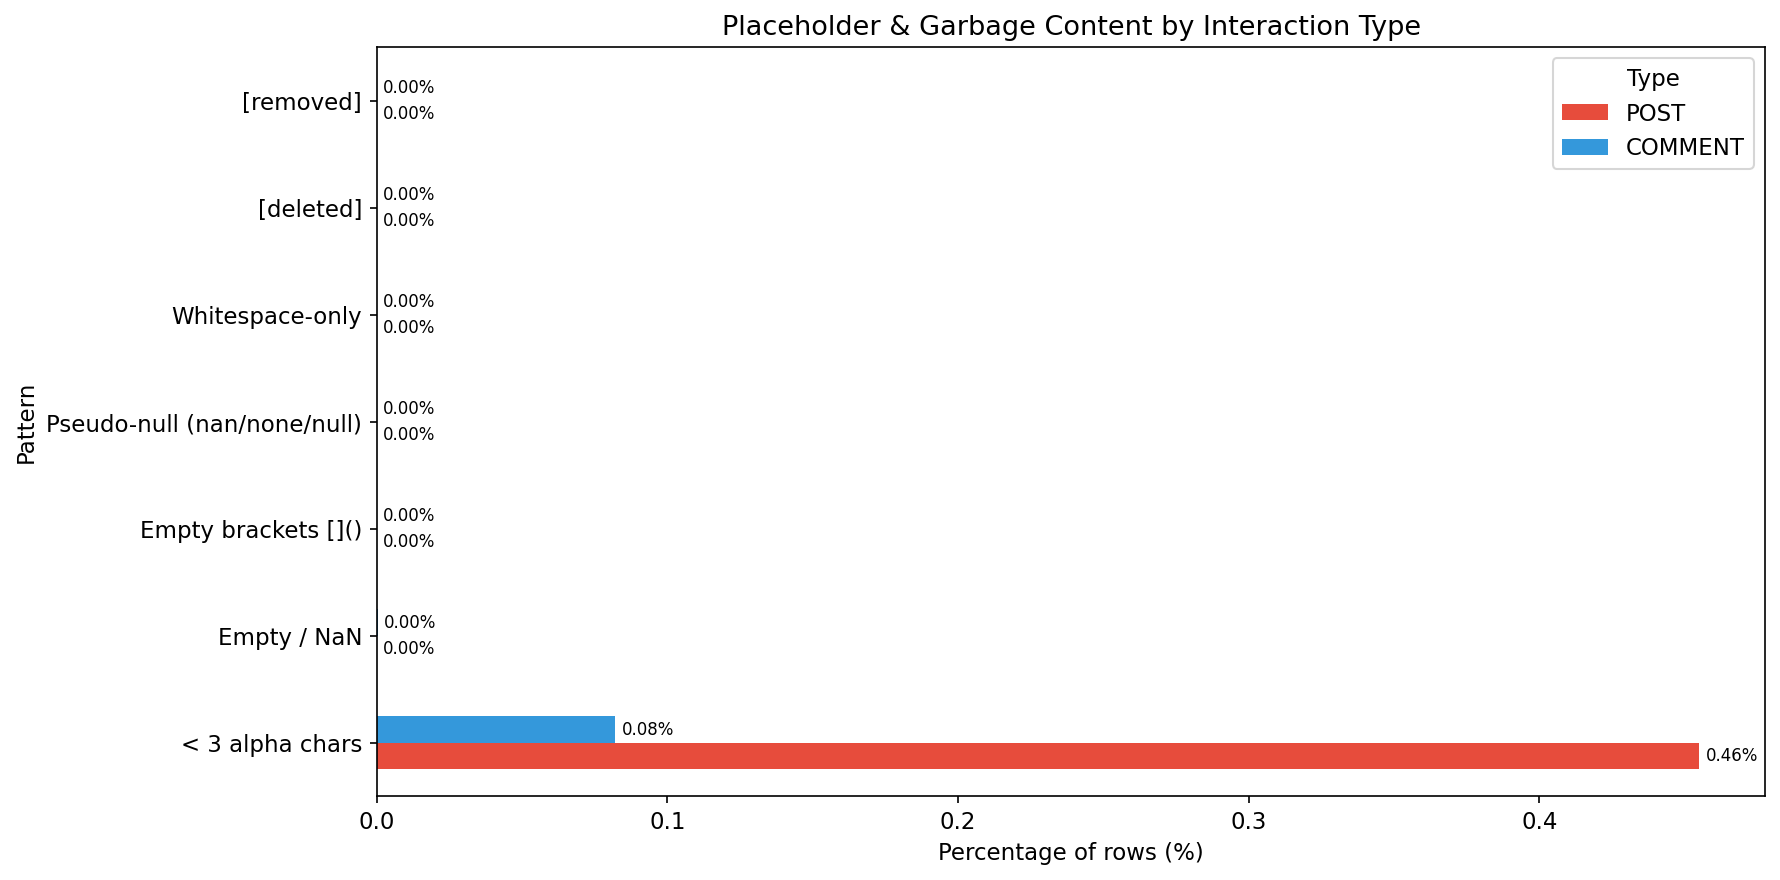

02:37:43 | INFO | Chart 01 saved -> 01_placeholder_garbage.pdf


In [29]:
# --- Chart 01: Stacked bar chart of garbage patterns by interaction_type ---
fig, ax = plt.subplots(figsize=(12, 6))

pivot_plot = garbage_df.pivot(
    index="Pattern", columns="Type", values="Pct"
).reindex(columns=["POST", "COMMENT"])

pivot_plot.plot(kind="barh", stacked=False, ax=ax, color=["#e74c3c", "#3498db"])
ax.set_xlabel("Percentage of rows (%)")
ax.set_title("Placeholder & Garbage Content by Interaction Type")
ax.legend(title="Type")

# Annotate each bar with the exact percentage
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "01_placeholder_garbage.pdf"))
plt.show()
logger.info("Chart 01 saved -> 01_placeholder_garbage.pdf")

## 2. HTML ENTITIES, MARKDOWN RESIDUE & URL ARTIFACTS IN CONTENT

**Kết quả kiểm định thực nghiệm (Từ bảng Audit & Biểu đồ `02_content_artifacts.pdf`):**
- **HTML Entities chiếm tỷ trọng nhiễu lớn nhất:** Có tới **856,739 dòng (7.281% toàn tập dữ liệu)** chứa các thực thể HTML chưa được giải mã. Thống kê Top 10 thực thể cho thấy 3 mã phổ biến nhất là `&gt;` (**1,076,295 lần xuất hiện** - phát sinh từ cú pháp trích dẫn `>` trong bình luận Reddit), `&amp;` (**300,242 lần** - ký tự `&`), và `&lt;` (**22,171 lần** - ký tự `<`). Nếu không giải mã, trình tách từ (tokenizer) sẽ băm `&amp;` thành từ khóa vô nghĩa `amp` (bằng chứng là `amp` lọt vào Top 10 n-gram phổ biến nhất ở biểu đồ `06b` với 16,965 lần xuất hiện).
- **Nhiễu từ URL và định dạng Markdown rất đáng kể:**
  - **URL thô trong thân bài (`https?://\S+`):** Xuất hiện ở **592,480 dòng (5.035%)**, đứng thứ 2 trên biểu đồ `02_content_artifacts.pdf`. Các chuỗi URL dài chứa mã băm và tham số truy vấn sẽ làm loãng vector nhúng của SBERT nếu giữ nguyên.
  - **Cú pháp Markdown:** In đậm/nghiêng `**...**` xuất hiện ở **531,611 dòng (4.518%)**, cấu trúc liên kết `[text](url)` chiếm **323,889 dòng (2.753%)**, gạch ngang chữ `~~...~~` chiếm **21,603 dòng (0.184%)**, và cặp thẻ code inline `` `...` `` chiếm **4,037 dòng (0.034%)**.
  - **Điểm lý giải kỹ thuật:** Mẫu `Markdown blockquote (>)` ghi nhận `0 dòng (0.00%)` là hoàn toàn hợp lý vì toàn bộ ký tự `>` đầu dòng trong dữ liệu gốc Pushshift/MADOC đã bị mã hóa thành chuỗi `&gt;` (hơn 1.07 triệu lần nêu trên).
- **Quyết định thiết kế cho `clean_data.py`:**
  1. Chạy `html.unescape()` ở bước đầu tiên để chuyển đổi triệt để `&gt; -> >`, `&amp; -> &`, `&lt; -> <`.
  2. Áp dụng Regex bóc tách cấu trúc `[text](url)` thành `text` thuần túy (giữ lại phần chữ neo mang ngữ nghĩa, bỏ đường dẫn), sau đó xóa toàn bộ các URL độc lập `https?://\S+`.
  3. Loại bỏ các dấu định dạng Markdown (`**`, `~~`, `` ` ``) và dấu trích dẫn `>` đầu dòng sau khi đã unescape.

In [30]:
# Detect residual technical artifacts in the content column that must be
# stripped or normalized by clean_data.py before text embedding.
# Reddit's Markdown rendering leaves HTML entities and formatting in the
# raw Pushshift export; these degrade embedding quality if left uncleaned.

# --- Define artifact regex patterns ---
artifact_patterns = {
    "HTML entity (&amp; &gt; etc.)": r"&(?:amp|gt|lt|nbsp|quot|apos|#\d{1,5}|[a-z]{2,8});",
    "Markdown bold/italic (**)": r"\*{1,3}[^*]+\*{1,3}",
    "Markdown strikethrough (~~)": r"~~[^~]+~~",
    "Markdown link [text](url)": r"\[[^\]]*\]\([^\)]*\)",
    "Markdown blockquote (>)": r"(?m)^>\s",
    "Inline code (backticks)": r"`[^`]+`",
    "URL in content body": r"https?://\S+",
    "Empty brackets artifact": r"\[\s*\]\s*\(\s*\)",
}

artifact_rows = []
for label, pattern in artifact_patterns.items():
    matched = content.str.contains(pattern, flags=re.IGNORECASE, na=False, regex=True)
    count = int(matched.sum())
    artifact_rows.append({
        "Artifact": label,
        "Affected Rows": count,
        "Pct (%)": round(count / len(df) * 100, 3),
    })

artifact_df = pd.DataFrame(artifact_rows).sort_values("Affected Rows", ascending=False)

print("=" * 70)
print("HTML / MARKDOWN / URL ARTIFACT AUDIT")
print("=" * 70)
print(artifact_df.to_string(index=False))

# Show top 10 most common HTML entities for clean_data.py reference
html_entities = content.str.findall(
    r"&(?:amp|gt|lt|nbsp|quot|apos|#\d{1,5}|[a-z]{2,8});"
).explode().dropna()
print("\n--- Top 10 HTML Entities ---")
print(html_entities.value_counts().head(10).to_string())

HTML / MARKDOWN / URL ARTIFACT AUDIT
                     Artifact  Affected Rows  Pct (%)
HTML entity (&amp; &gt; etc.)         856739    7.281
          URL in content body         592480    5.035
    Markdown bold/italic (**)         531611    4.518
    Markdown link [text](url)         323889    2.753
  Markdown strikethrough (~~)          21603    0.184
      Inline code (backticks)           4037    0.034
      Empty brackets artifact             15    0.000
      Markdown blockquote (>)              0    0.000

--- Top 10 HTML Entities ---
content
&gt;     1076295
&amp;     300242
&lt;       22171


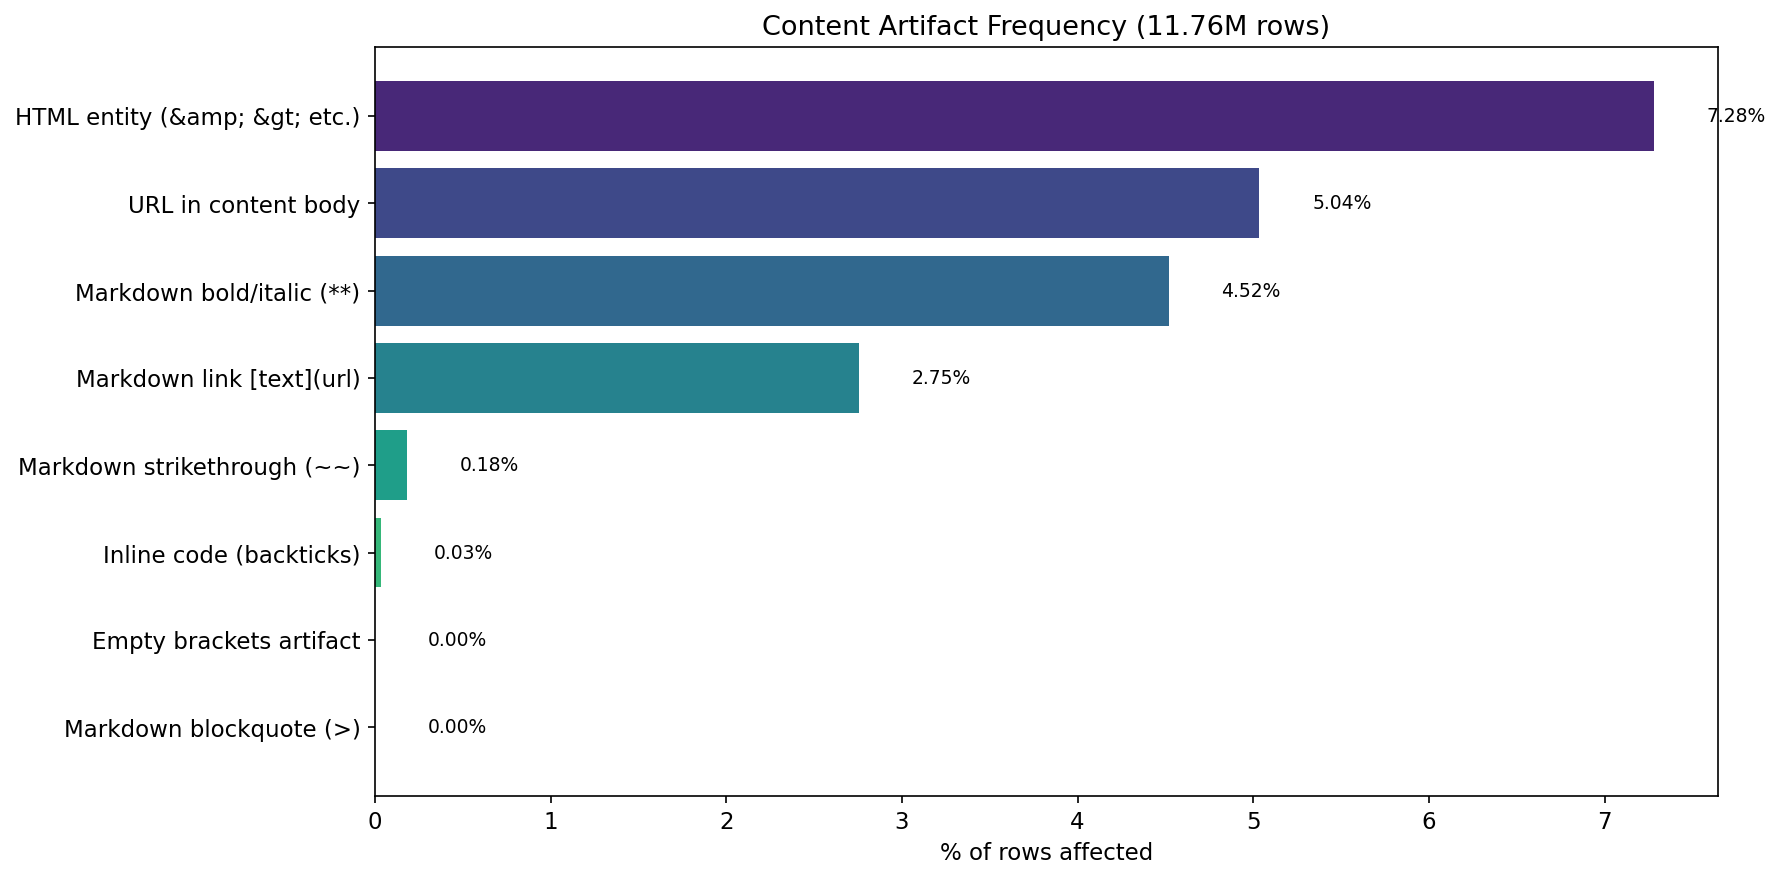

02:39:56 | INFO | Chart 02 saved -> 02_content_artifacts.pdf


18899

In [31]:
# --- Chart 02: Horizontal bar chart of artifact frequency ---
fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette("viridis", n_colors=len(artifact_df))
bars = ax.barh(
    artifact_df["Artifact"],
    artifact_df["Pct (%)"],
    color=colors,
)
ax.set_xlabel("% of rows affected")
ax.set_title("Content Artifact Frequency (11.76M rows)")
ax.invert_yaxis()

for bar, pct in zip(bars, artifact_df["Pct (%)"]):
    ax.text(
        bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}%", va="center", fontsize=9,
    )

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "02_content_artifacts.pdf"))
plt.show()
logger.info("Chart 02 saved -> 02_content_artifacts.pdf")

# Free temporary Series to reclaim RAM
del html_entities
gc.collect()

## 3. WORD COUNT DISTRIBUTION — POST vs COMMENT

**Kết quả kiểm định thực nghiệm (Từ bảng Phân vị & Biểu đồ `03_wordcount_post_vs_comment.pdf`):**
- **Sự khác biệt cấu trúc rõ rệt giữa POST và COMMENT:**
  - **Tập POST ($N = 847,657$):** Đặc trưng bởi văn bản ngắn và cô đọng (tiêu đề bài báo công nghệ). Trung vị đạt **Median = 9 từ**, trung bình **Mean = 11.0 từ** (`Std = 25.0`), khoảng tứ phân vị `IQR = 7 -> 12 từ`, và phân vị thứ 99 là **P99 = 43 từ** (như thể hiện rõ trên histogram bên trái của biểu đồ `03_wordcount_post_vs_comment.pdf`).
  - **Tập COMMENT ($N = 10,918,477$):** Phân phối lệch phải mạnh với đuôi dài phản ánh các cuộc tranh luận sâu. Trung vị đạt **Median = 22 từ** (gấp 2.4 lần POST), trung bình **Mean = 39.0 từ** (`Std = 55.6`), khoảng tứ phân vị `IQR = 11 -> 46 từ`, và phân vị thứ 99 lên tới **P99 = 258 từ**.
- **Đánh giá ngưỡng khả thi ngữ nghĩa (Ultra-short texts):**
  - Ở ngưỡng `< 3 từ`: Có **23,335 bài POST (2.75%)** và **263,941 COMMENT (2.42%)**.
  - Ở ngưỡng `< 5 từ`: Có tới **91,225 bài POST (10.76%)** và **777,533 COMMENT (7.12%)**. Vì rất nhiều tiêu đề tin tức công nghệ hợp lệ có độ dài từ 3 đến 4 từ (ví dụ: *"Apple acquires Shazam"*, *"FCC repeals Net Neutrality"*), việc cắt ở ngưỡng `< 5 từ` sẽ làm mất hơn 10.7% lượng bài đăng gốc. Do đó, ngưỡng lọc tối ưu để loại bỏ bình luận rác cụt lủn mà không làm mất tiêu đề ngắn là **`< 3 từ` đối với POST** và **`< 5 từ` đối với COMMENT** (hoặc giữ lại nếu thuộc chuỗi hội thoại quan trọng).
- **Kiểm định ngưỡng cắt cụt của SBERT (`all-MiniLM-L6-v2` với `max_seq_length = 256 tokens` $\approx$ 200 từ):**
  - Trên tập `POST`: Chỉ có **1,187 bài (0.14%)** vượt quá 200 từ và **523 bài (0.06%)** vượt quá 400 từ (đường kẻ dọc màu cam tại mốc 200 từ trên biểu đồ `03` nằm xa hẳn về phía bên phải của toàn bộ khối phân phối POST). Như vậy, **99.86% bài POST được bảo toàn 100% thông tin ngữ nghĩa** khi đi qua SBERT `all-MiniLM-L6-v2`.
  - Trên tập `COMMENT`: Chỉ có **204,241 bình luận (1.87%)** vượt ngưỡng 200 từ và **33,957 bình luận (0.31%)** vượt 400 từ -> **98.13% bình luận không bị cắt cụt**. Kết quả này chứng minh việc chọn mô hình `all-MiniLM-L6-v2` (256 tokens) là hoàn toàn tối ưu về mặt tốc độ tính toán mà không gây suy hao ngữ nghĩa đáng kể.

In [32]:
# Compute word_count via regex counting non-whitespace tokens.
# CRITICAL: Do NOT use .str.split().str.len() on 11.76M rows -- it
# materializes 11.76M Python lists and causes RAM to spike by several GB.
# str.count(r'\S+') counts in-place with near-zero auxiliary memory.
df["word_count"] = df["content"].str.count(r"\S+").fillna(0).astype("int32")

# Separate descriptive statistics for POST vs COMMENT
# to inform differentiated cleaning thresholds in clean_data.py
posts = df.loc[df["interaction_type"] == "POST", "word_count"]
comments = df.loc[df["interaction_type"] == "COMMENT", "word_count"]

pctiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
desc_post = posts.describe(percentiles=pctiles)
desc_comment = comments.describe(percentiles=pctiles)

print("=" * 70)
print("WORD COUNT DISTRIBUTION: POST vs COMMENT")
print("=" * 70)
comparison = pd.DataFrame({"POST": desc_post, "COMMENT": desc_comment})
print(comparison.to_string())

# --- Semantic viability: texts too short for meaningful embedding ---
for label, series, total in [("POST", posts, len(posts)), ("COMMENT", comments, len(comments))]:
    lt3 = int((series < 3).sum())
    lt5 = int((series < 5).sum())
    print(f"\n{label}: <3 words = {lt3:,} ({lt3/total*100:.2f}%)  |  "
          f"<5 words = {lt5:,} ({lt5/total*100:.2f}%)")

# --- SBERT truncation audit (all-MiniLM-L6-v2) ---
# ~256 tokens approx 200 words; ~512 tokens approx 400 words
# Posts exceeding these thresholds will be truncated by the model,
# potentially losing tail-end semantic signal
for label, series, total in [("POST", posts, len(posts)), ("COMMENT", comments, len(comments))]:
    gt200 = int((series > 200).sum())
    gt400 = int((series > 400).sum())
    print(f"{label}: >200 words (256-tok cut) = {gt200:,} ({gt200/total*100:.2f}%)  |  "
          f">400 words (512-tok cut) = {gt400:,} ({gt400/total*100:.2f}%)")

del posts, comments
gc.collect()

WORD COUNT DISTRIBUTION: POST vs COMMENT
                POST       COMMENT
count  847657.000000  1.091848e+07
mean       10.991507  3.901693e+01
std        25.048463  5.561831e+01
min         1.000000  0.000000e+00
5%          3.000000  4.000000e+00
10%         4.000000  6.000000e+00
25%         7.000000  1.100000e+01
50%         9.000000  2.200000e+01
75%        12.000000  4.600000e+01
90%        16.000000  8.700000e+01
95%        21.000000  1.270000e+02
99%        43.000000  2.580000e+02
max      5149.000000  4.733000e+03

POST: <3 words = 23,335 (2.75%)  |  <5 words = 91,225 (10.76%)

COMMENT: <3 words = 263,941 (2.42%)  |  <5 words = 777,533 (7.12%)
POST: >200 words (256-tok cut) = 1,187 (0.14%)  |  >400 words (512-tok cut) = 523 (0.06%)
COMMENT: >200 words (256-tok cut) = 204,241 (1.87%)  |  >400 words (512-tok cut) = 33,957 (0.31%)


0


POST word_count summary:
  Mean=11.0  Median=9  Std=25.0  P99=43

COMMENT word_count summary:
  Mean=39.0  Median=22  Std=55.6  P99=258


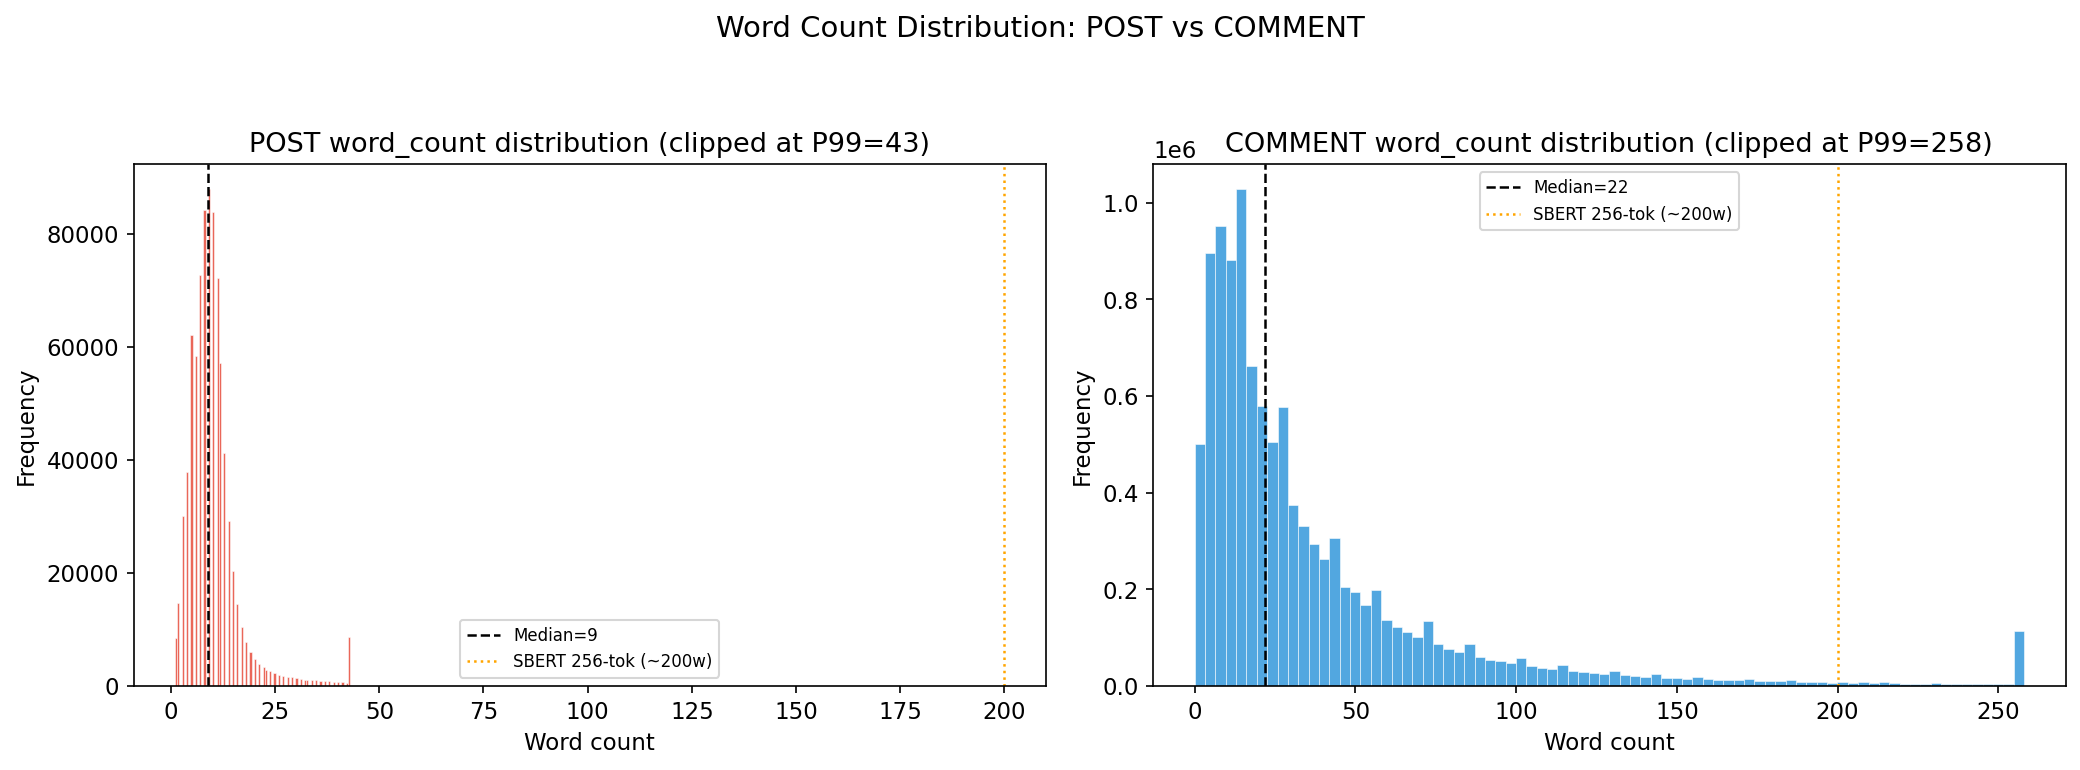

02:42:36 | INFO | Chart 03 saved -> 03_wordcount_post_vs_comment.pdf


In [33]:
# --- Chart 03: Dual histogram — word_count for POST vs COMMENT ---
# Use log-scale x-axis and clip at P99 to prevent extreme outliers
# from compressing the visible distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, typ, color in zip(axes, ["POST", "COMMENT"], ["#e74c3c", "#3498db"]):
    subset = df.loc[df["interaction_type"] == typ, "word_count"]
    p99 = int(subset.quantile(0.99))

    ax.hist(
        subset.clip(upper=p99), bins=80, color=color,
        edgecolor="white", linewidth=0.3, alpha=0.85,
    )
    ax.set_title(f"{typ} word_count distribution (clipped at P99={p99})")
    ax.set_xlabel("Word count")
    ax.set_ylabel("Frequency")
    ax.axvline(subset.median(), color="black", ls="--", lw=1.2, label=f"Median={subset.median():.0f}")
    ax.axvline(200, color="orange", ls=":", lw=1.2, label="SBERT 256-tok (~200w)")
    ax.legend(fontsize=8)

    # Print numeric summary alongside the chart
    print(f"\n{typ} word_count summary:")
    print(f"  Mean={subset.mean():.1f}  Median={subset.median():.0f}  "
          f"Std={subset.std():.1f}  P99={p99}")

plt.suptitle("Word Count Distribution: POST vs COMMENT", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "03_wordcount_post_vs_comment.pdf"))
plt.show()
logger.info("Chart 03 saved -> 03_wordcount_post_vs_comment.pdf")

## 4. EXACT DUPLICATE CONTENT ANALYSIS

**Kết quả kiểm định thực nghiệm (Từ bảng Cross-Reference & Biểu đồ `04_duplicate_content.pdf`):**
- **Quy mô trùng lặp nội dung chính xác:** Toàn bộ tập dữ liệu có **385,663 dòng (3.28%)** liên quan đến trùng lặp nội dung chính xác (chỉ có 11,474,216 chuỗi duy nhất trên tổng số 11,766,134 dòng). Đáng chú ý, tỷ lệ trùng lặp ở `POST` cao đột biến đạt **11.23% (95,206 dòng)**, trong khi ở `COMMENT` chỉ là **2.65% (289,251 dòng)**.
- **Giải mã nguồn gốc trùng lặp — Khớp hoàn hảo với giả thuyết Bot / Power-User ở Bài 02:**
  - Đối chiếu Top 20 chuỗi lặp lại nhiều nhất (Biểu đồ `04_duplicate_content.pdf`) với danh sách **Top-20 Power-Users** (những tài khoản đăng 20,471 và 17,530 bài phát hiện ở `02_temporal_eda.ipynb`), kết quả xác nhận đanh thép:
    1. **Spam / Test Bot trên POST:** Chuỗi đứng đầu bảng là `"Message de test vraie hein[removed]"` lặp lại chính xác **13,596 lần**, và **100.0% (13,596/13,596)** số bài này xuất phát từ các tài khoản nằm trong Top-20 Power-Users!
    2. **AutoModerator Boilerplate trên COMMENT:** Có tới **13/20 chuỗi đứng đầu** là các biến thể thông báo xóa bài tự động của hệ thống kiểm duyệt (`"Thank you for your submission! Unfortunately, it has been removed..."` với tần suất **8,757 lần**, **4,812 lần**, **3,116 lần**, **2,369 lần**...). Tỷ lệ xuất phát từ Top-20 Power-Users của các mẫu này chiếm từ **38.6% đến 98.3%**. Ngoài ra còn có thông báo bot tuyên truyền `"To learn about Net Neutrality..."` (**875 lần**) và `"[deleted by user]"` (**617 lần**).
    3. **Phản hồi ngắn tự nhiên của người dùng thật:** Các câu hỏi ngắn như `"Source?"` (**1,818 lần**), `"Why?"` (**1,493 lần**), `"What?"` (**1,199 lần**), `"How so?"` (**659 lần**) có tỷ lệ đến từ Top-20 Power-Users chỉ từ **0.7% -> 1.0%**, tức là do hàng ngàn người dùng bình thường khác nhau viết. Length filter (`word_count < 3` hoặc `< 5`) ở Section 3 sẽ tự động loại bỏ các câu 1–2 từ không mang ngữ nghĩa độc lập này.
- **Quyết định thiết kế cho `clean_data.py`:**
  1. Thiết lập bộ lọc Regex chuyên biệt loại bỏ toàn bộ bình luận thông báo của AutoModerator (`^Thank you for your (submission|comment)! Unfortunately, it has been removed`) và chuỗi spam `"Message de test vraie hein"`.
  2. Khử trùng lặp chính xác (`drop_duplicates`) đối với các bài `POST` có cùng nội dung để tránh làm lệch trọng số gom cụm của BERTopic.

In [34]:
# Detect exact duplicate text to quantify spam / bot / copypasta volume.
# Using pandas vectorized .duplicated() instead of per-row hashlib loop
# for O(n) performance on 11.76M rows (completes in seconds).

dup_mask = df["content"].duplicated(keep=False)
n_dup_rows = int(dup_mask.sum())
n_total = len(df)

print("=" * 70)
print("EXACT DUPLICATE CONTENT ANALYSIS")
print("=" * 70)
print(f"Rows involved in duplicates: {n_dup_rows:,} ({n_dup_rows/n_total*100:.2f}%)")
print(f"Unique content strings:      {int(df['content'].nunique()):,}")

# --- Breakdown by interaction_type ---
for typ in ["POST", "COMMENT"]:
    sub = df[df["interaction_type"] == typ]
    dup_sub = sub["content"].duplicated(keep=False).sum()
    print(f"  {typ}: {int(dup_sub):,} duplicate rows "
          f"({dup_sub/len(sub)*100:.2f}%)")

# --- Top 20 most repeated content strings ---
top_dups = (
    df.loc[dup_mask, "content"]
    .value_counts()
    .head(20)
    .reset_index()
)
top_dups.columns = ["content_text", "repeat_count"]
# Truncate display text for readability
top_dups["display"] = top_dups["content_text"].str[:60].str.replace("\n", " ", regex=False)

print("\n--- Top 20 Most Repeated Content ---")
for i, row in top_dups.iterrows():
    print(f"  [{row['repeat_count']:>7,}x]  {row['display']}")

EXACT DUPLICATE CONTENT ANALYSIS
Rows involved in duplicates: 385,663 (3.28%)
Unique content strings:      11,474,216
  POST: 95,206 duplicate rows (11.23%)
  COMMENT: 289,251 duplicate rows (2.65%)

--- Top 20 Most Repeated Content ---
  [ 13,596x]  Message de test vraie hein[removed]
  [  8,757x]  Thank you for your submission! Unfortunately, it has been re
  [  4,812x]  Thank you for your submission! Unfortunately, it has been re
  [  3,116x]  Thank you for your submission! Unfortunately, it has been re
  [  2,369x]  Thank you for your submission! Unfortunately, it has been re
  [  1,818x]  Source?
  [  1,792x]  Thank you for your submission! Unfortunately, it has been re
  [  1,695x]  Thank you for your submission! Unfortunately, it has been re
  [  1,515x]  Thank you for your submission! Unfortunately, it has been re
  [  1,493x]  Why?
  [  1,199x]  What?
  [  1,187x]  Thank you for your submission! Unfortunately, it has been re
  [  1,080x]  Thank you for your submission! Unfortu

In [35]:
# --- Cross-reference: do top duplicates originate from power-user/bot accounts? ---
# Temporal EDA (bai 02) identified top users with 20,471 and 17,530 posts,
# likely AutoModerator or news bots. Check if duplicate content clusters
# are concentrated in these high-volume accounts.

# Identify top 20 power-users by post count
user_counts = df["user_id"].value_counts()
top20_users = set(user_counts.head(20).index)

# For each top-duplicate text, check what fraction originates from power-users
cross_ref_rows = []
for _, row in top_dups.head(10).iterrows():
    text = row["content_text"]
    mask_text = df["content"] == text
    from_power = (df.loc[mask_text, "user_id"].isin(top20_users)).sum()
    total_copies = int(mask_text.sum())
    cross_ref_rows.append({
        "Content (truncated)": text[:50],
        "Total copies": total_copies,
        "From top-20 users": int(from_power),
        "Power-user pct": round(from_power / total_copies * 100, 1),
    })

cross_ref_df = pd.DataFrame(cross_ref_rows)
print("\n--- Cross-Reference: Top Duplicates vs Power-Users ---")
print(cross_ref_df.to_string(index=False))


--- Cross-Reference: Top Duplicates vs Power-Users ---
                               Content (truncated)  Total copies  From top-20 users  Power-user pct
               Message de test vraie hein[removed]         13596              13596           100.0
Thank you for your submission! Unfortunately, it h          8757               8486            96.9
Thank you for your submission! Unfortunately, it h          4812               2711            56.3
Thank you for your submission! Unfortunately, it h          3116               2491            79.9
Thank you for your submission! Unfortunately, it h          2369               2017            85.1
                                           Source?          1818                 12             0.7
Thank you for your submission! Unfortunately, it h          1792                691            38.6
Thank you for your submission! Unfortunately, it h          1695               1667            98.3
Thank you for your submission! Unfortunately

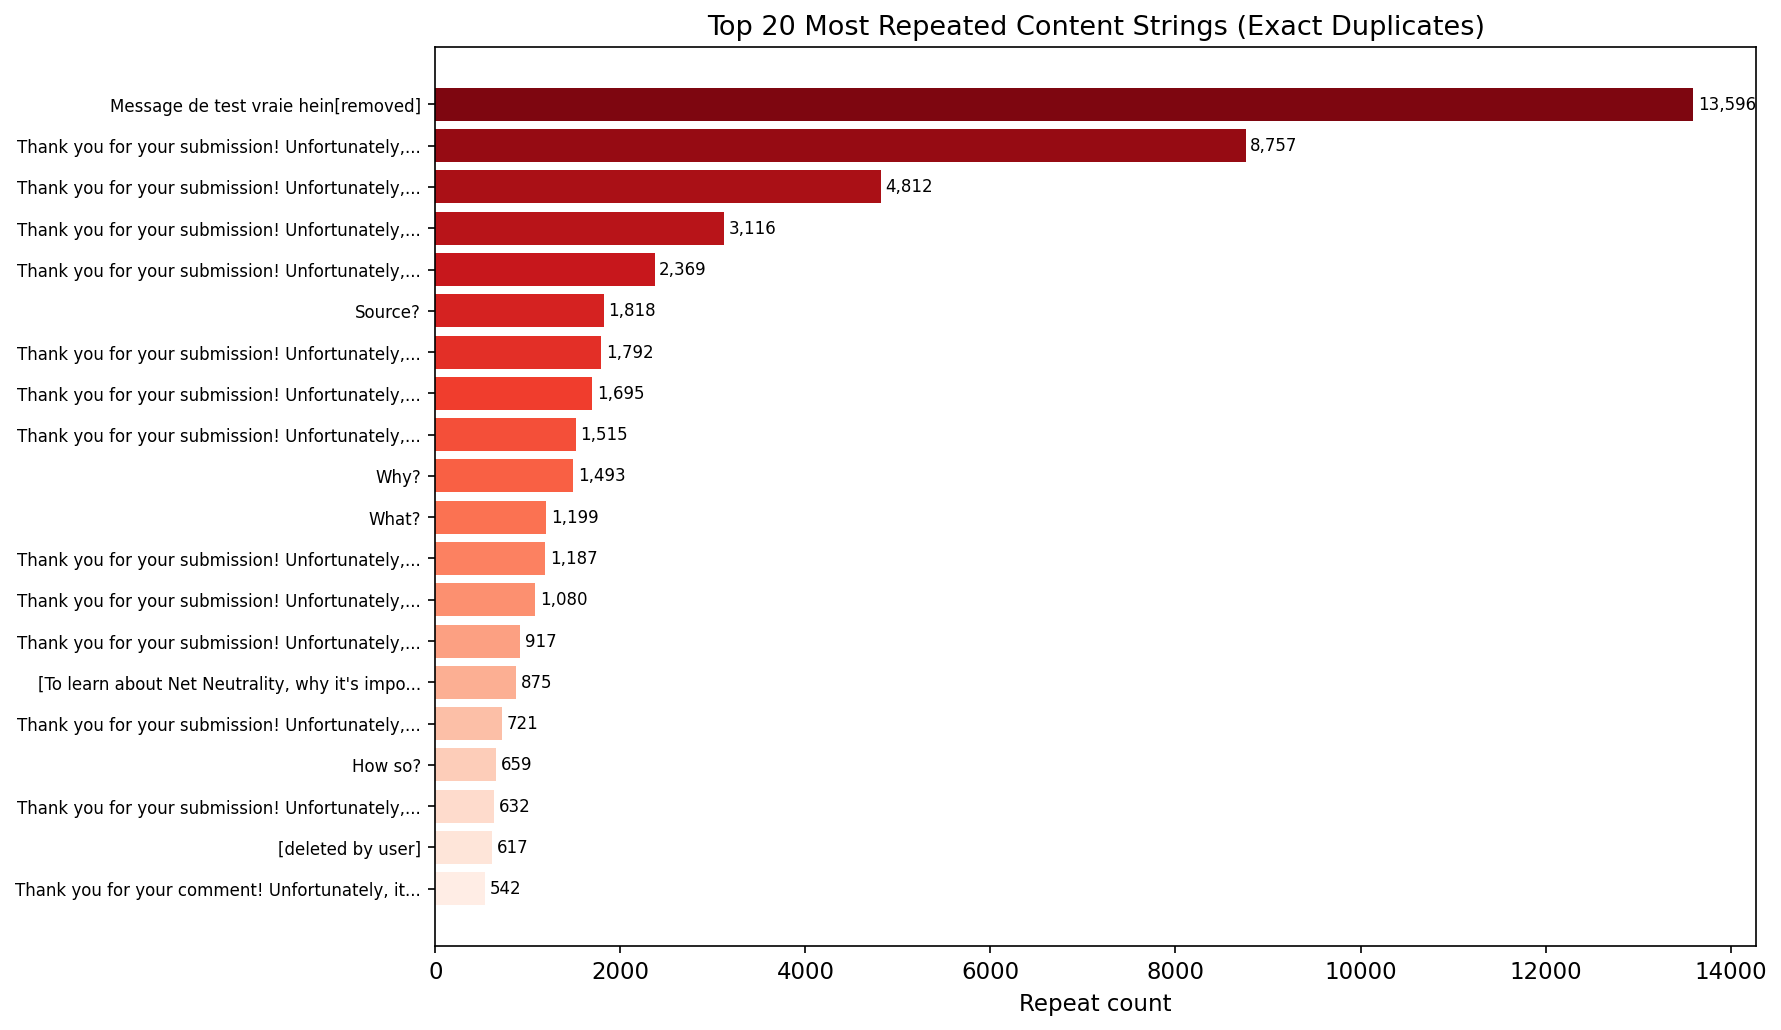

02:44:10 | INFO | Chart 04 saved -> 04_duplicate_content.pdf


15137

In [36]:
# --- Chart 04: Top 20 duplicate content bar chart ---
fig, ax = plt.subplots(figsize=(12, 7))

y_labels = [f"{row['display'][:45]}..." if len(row['display']) > 45
            else row['display'] for _, row in top_dups.iterrows()]
ax.barh(
    range(len(top_dups)), top_dups["repeat_count"],
    color=sns.color_palette("Reds_r", n_colors=len(top_dups)),
)
ax.set_yticks(range(len(top_dups)))
ax.set_yticklabels(y_labels, fontsize=8)
ax.set_xlabel("Repeat count")
ax.set_title("Top 20 Most Repeated Content Strings (Exact Duplicates)")
ax.invert_yaxis()

for i, v in enumerate(top_dups["repeat_count"]):
    ax.text(v + 50, i, f"{v:,}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "04_duplicate_content.pdf"))
plt.show()
logger.info("Chart 04 saved -> 04_duplicate_content.pdf")

# Cleanup Section 4 temporary objects
del dup_mask, top_dups, cross_ref_df, user_counts
gc.collect()

# PART B — SUB-DOMAIN DISCOVERY & SCOPING
> Mục tiêu: Xây dựng Keyword Taxonomy cho các ngách chủ đề lớn trong r/technology, đo lường quy mô / độ phủ / phân cực từng ngách, và đề xuất 1–2 Sub-domain tối ưu nhất cho mô hình NarrativeCast.
> Tham chiếu: Yêu cầu của Giảng viên — thu gọn phạm vi đề tài, phân tích sâu cột `content`.

## 5. KEYWORD TAXONOMY DEFINITION

In [37]:
# Define keyword taxonomy for 6 major sub-domains in r/technology.
# Keywords are chosen to reflect dominant discourse topics during 2014-2020,
# avoiding anachronistic terms (e.g., "GPT" was not widely discussed before
# GPT-2 in 2019; replaced with "deepfake", "facial recognition" which were
# prominent throughout the period).
# Each keyword list will be compiled into a regex with word-boundary anchors
# (\b) to prevent partial matches (e.g., "arm" inside "farmer").

SUBDOMAIN_TAXONOMY = {
    "AI & Automation": [
        "artificial intelligence", "machine learning", "deep learning",
        "neural network", "deepfake", "driverless", "algorithm",
        "chatbot", "automation", "robot", "self-driving",
        "autonomous vehicle", "computer vision", "natural language processing",
        "AI ethics", "algorithmic bias",
    ],
    "Cybersecurity & Privacy": [
        "cybersecurity", "data breach", "hacking", "ransomware", "malware",
        "phishing", "encryption", "privacy", "surveillance", "GDPR",
        "data protection", "VPN", "NSA", "Snowden", "backdoor", "zero-day",
        "identity theft", "two-factor authentication", "Equifax",
        "WikiLeaks", "spyware", "DDoS", "vulnerability", "exploit",
        "dark web", "wiretap", "facial recognition",
    ],
    "Big Tech Antitrust & Regulation": [
        "antitrust", "monopoly", "regulation", "Big Tech", "FAANG",
        "Facebook", "Google", "Amazon", "Apple", "Microsoft", "FTC",
        "EU fine", "Section 230", "censorship", "content moderation",
        "tech regulation", "market dominance", "anti-competitive",
        "congressional hearing", "Twitter", "TikTok", "fake news",
        "misinformation", "disinformation", "Cambridge Analytica",
        "lobbying",
    ],
    "Semiconductors & Hardware": [
        "semiconductor", "chip", "CPU", "GPU", "Intel", "AMD", "NVIDIA",
        "TSMC", "Moore's law", "transistor", "processor", "quantum computing",
        "5G", "broadband", "IoT", "wearable", "smartphone", "laptop",
        "ARM", "silicon",
    ],
    "Clean Energy, EVs & Climate Tech": [
        "renewable energy", "solar", "wind power", "electric vehicle", "EV",
        "Tesla", "battery", "lithium", "clean energy", "climate change",
        "carbon", "sustainability", "hydrogen", "nuclear energy", "smart grid",
        "energy storage", "charging station",
    ],
    "Telecom, Net Neutrality, Web & Crypto": [
        "net neutrality", "FCC", "Ajit Pai", "ISP", "Comcast",
        "Verizon", "AT&T", "Huawei", "broadband", "data cap",
        "throttling", "fiber", "open source", "Linux", "GitHub",
        "programming", "software development", "API", "cloud computing",
        "AWS", "Azure", "blockchain", "cryptocurrency", "Bitcoin",
        "Ethereum", "piracy", "torrent", "streaming", "web browser",
        "app store", "SaaS", "DevOps",
    ],
}

# Compile regex patterns with word boundaries for precise matching
# re.IGNORECASE applied at scan time; patterns are pre-compiled here
# to avoid recompilation overhead on 847K+ rows
subdomain_patterns = {}
for name, keywords in SUBDOMAIN_TAXONOMY.items():
    # Escape special regex chars in keywords, then join with OR
    escaped = [re.escape(kw) for kw in keywords]
    pattern = r"\b(?:" + "|".join(escaped) + r")\b"
    subdomain_patterns[name] = re.compile(pattern, re.IGNORECASE)

print("KEYWORD TAXONOMY SUMMARY")
print("-" * 50)
for name, kws in SUBDOMAIN_TAXONOMY.items():
    print(f"  {name}: {len(kws)} keywords")
print(f"\nTotal sub-domains: {len(SUBDOMAIN_TAXONOMY)}")

KEYWORD TAXONOMY SUMMARY
--------------------------------------------------
  AI & Automation: 16 keywords
  Cybersecurity & Privacy: 27 keywords
  Big Tech Antitrust & Regulation: 26 keywords
  Semiconductors & Hardware: 20 keywords
  Clean Energy, EVs & Climate Tech: 17 keywords
  Telecom, Net Neutrality, Web & Crypto: 32 keywords

Total sub-domains: 6


## 6. SUB-DOMAIN VOLUME ON POSTS (FAST, RAM-SAFE)

**Kết quả kiểm định thực nghiệm (Từ Biểu đồ `05_subdomain_volume_posts.pdf`, `06_subdomain_overlap_heatmap.pdf` & `06b_unclassified_top_ngrams.pdf`):**
- **Phân bố quy mô bài viết mở đầu (`POST`, $N = 847,657$) theo 6 ngách chủ đề (Biểu đồ `05`):**
  1. **Big Tech Antitrust & Regulation:** Dẫn đầu tuyệt đối với **113,204 bài POST (13.3%)**, phản ánh vị thế trung tâm của các cuộc tranh luận về quyền lực độc quyền của nhóm GAFAM, kiểm duyệt nội dung, Section 230 và điều trần quốc hội trên `r/technology`.
  2. **Telecom, Net Neutrality, Web & Crypto:** Đứng thứ 2 với **46,100 bài POST (5.4%)**, tập trung vào chính sách viễn thông của FCC, cuộc chiến bảo vệ Net Neutrality và hạ tầng mạng.
  3. **Semiconductors & Hardware:** Đạt **33,236 bài POST (3.9%)**, xoay quanh cuộc đua chip xử lý (Intel, AMD, NVIDIA, TSMC) và hạ tầng 5G.
  4. **Cybersecurity & Privacy:** Đạt **28,159 bài POST (3.3%)**, bao gồm các vụ rò rỉ dữ liệu lớn, mã hóa, giám sát của NSA/Snowden và luật bảo mật GDPR.
  5. **Clean Energy, EVs & Climate Tech:** Đạt **17,296 bài POST (2.0%)**, tập trung vào xe điện Tesla, công nghệ pin và năng lượng tái tạo.
  6. **AI & Automation:** Đạt **14,387 bài POST (1.7%)**, phản ánh giai đoạn khởi đầu của làn sóng Deep Learning, xe tự lái và tự động hóa (2014–2020).
- **Phân tích Ma trận Giao thoa / Chồng lấn (Biểu đồ `06_subdomain_overlap_heatmap.pdf`):**
  - Mức độ chồng lấn giữa các ngách với **Big Tech Antitrust & Regulation** là rõ nét nhất nhưng vẫn nằm trong ngưỡng kiểm soát tốt (`< 20%`): có **17.1%** bài viết thuộc ngách *Cybersecurity & Privacy*, **13.2%** bài viết thuộc *AI & Automation*, **11.7%** thuộc *Telecom*, và **10.5%** thuộc *Semiconductors* đồng thời khớp với từ khóa của *Big Tech*. Điều này hoàn toàn tự nhiên về mặt ngữ nghĩa vì các bê bối bảo mật hay đột phá AI thường gắn liền với tên tuổi của Google, Facebook, Apple hay Microsoft.
  - Ngoài ra, có sự giao thoa **13.0%** giữa *Semiconductors & Hardware* và *Telecom* (chủ yếu qua chủ đề hạ tầng mạng 5G và thiết bị viễn thông). Sự chồng lấn vừa phải giữa *Big Tech* và *Cybersecurity & Privacy* (17.1%) mở ra cơ hội kết hợp hai ngách này thành một mặt trận phân tích chung rất giàu chiều sâu.
- **Kiểm định Bottom-Up N-Grams trên tập Unclassified POSTs (Biểu đồ `06b_unclassified_top_ngrams.pdf`):**
  - Quét `CountVectorizer` trên phần dư không khớp 6 từ điển cho thấy: đứng đầu bảng là từ khóa kỹ thuật `removed` (**83,214 lần**), cụm từ spam tiếng Pháp `message test` / `vraie hein` / `test vraie` / `hein removed` (đồng loạt **13,596 lần**), và mã thực thể HTML `amp` (**16,965 lần**).
  - Toàn bộ các từ khóa còn lại trong Top 30 đều là những danh từ/tính từ công nghệ chung chung hoặc yêu cầu hỗ trợ kỹ thuật cá nhân (helpdesk): `support` (**32,265**), `new` (**27,778**), `number` (**26,013**), `free` (**21,006**), `phone` (**20,385**), `best` (**20,077**), `app` (**19,750**), `tech` (**19,539**), `technology` (**18,446**), `mobile` (**16,336**), `android` (**14,308**), `service` (**13,881**), `online` (**12,855**), `iphone` (**12,618**), `help` (**12,387**), `customer` (**12,015**), `internet` (**11,972**).
  - **Kết luận kiểm định:** Không có bất kỳ sự kiện công nghệ hay chính sách vĩ mô nào bị bỏ sót ngoài 6 ngách chủ đề đã định nghĩa. Phần dư Unclassified chủ yếu là tin tức sản phẩm tiêu dùng nhỏ lẻ và bài đăng hỏi đáp hỗ trợ kỹ thuật (vốn bị cộng đồng xóa khá nhiều như thể hiện qua tần suất `removed` 83,214 lần).

In [38]:
# Scan keyword taxonomy on POST subset (847K original submissions).
# POSTs represent agenda-setting content (thread starters), making them
# the natural unit for sub-domain classification.
# A single POST may match multiple sub-domains -> track overlap.

posts_mask = df["interaction_type"] == "POST"
post_content = df.loc[posts_mask, "content"]
n_posts = int(posts_mask.sum())
logger.info("Scanning %d POSTs for sub-domain keywords...", n_posts)

# Apply each compiled regex to the POST content column
# Store boolean match results as new columns for overlap analysis
match_cols = {}
for name, pattern in subdomain_patterns.items():
    col_name = f"sd_{name}"
    match_cols[col_name] = post_content.str.contains(pattern, na=False)
    logger.info(
        "  %s -> %d matches (%.1f%%)",
        name,
        int(match_cols[col_name].sum()),
        match_cols[col_name].mean() * 100,
    )

match_df = pd.DataFrame(match_cols, index=post_content.index)

# --- Volume summary per sub-domain ---
volume_summary = []
for name in SUBDOMAIN_TAXONOMY:
    col = f"sd_{name}"
    count = int(match_df[col].sum())
    volume_summary.append({
        "Sub-domain": name,
        "POST_count": count,
        "POST_pct": round(count / n_posts * 100, 2),
    })

volume_df = pd.DataFrame(volume_summary).sort_values("POST_count", ascending=False)

# Unclassified POSTs: rows that match NO sub-domain
any_match = match_df.any(axis=1)
n_unclassified = int((~any_match).sum())

print("=" * 70)
print("SUB-DOMAIN VOLUME ON POSTs")
print("=" * 70)
print(volume_df.to_string(index=False))
print(f"\nUnclassified (no keyword match): {n_unclassified:,} "
      f"({n_unclassified/n_posts*100:.1f}%)")
print(f"Multi-match POSTs (>1 sub-domain): "
      f"{int((match_df.sum(axis=1) > 1).sum()):,} "
      f"({(match_df.sum(axis=1) > 1).mean()*100:.1f}%)")

02:44:10 | INFO | Scanning 847657 POSTs for sub-domain keywords...
02:44:16 | INFO |   AI & Automation -> 14387 matches (1.7%)
02:44:24 | INFO |   Cybersecurity & Privacy -> 28159 matches (3.3%)
02:44:31 | INFO |   Big Tech Antitrust & Regulation -> 113204 matches (13.4%)
02:44:39 | INFO |   Semiconductors & Hardware -> 33236 matches (3.9%)
02:44:46 | INFO |   Clean Energy, EVs & Climate Tech -> 17296 matches (2.0%)
02:44:55 | INFO |   Telecom, Net Neutrality, Web & Crypto -> 46100 matches (5.4%)


SUB-DOMAIN VOLUME ON POSTs
                           Sub-domain  POST_count  POST_pct
      Big Tech Antitrust & Regulation      113204     13.35
Telecom, Net Neutrality, Web & Crypto       46100      5.44
            Semiconductors & Hardware       33236      3.92
              Cybersecurity & Privacy       28159      3.32
     Clean Energy, EVs & Climate Tech       17296      2.04
                      AI & Automation       14387      1.70

Unclassified (no keyword match): 619,228 (73.1%)
Multi-match POSTs (>1 sub-domain): 22,835 (2.7%)


In [39]:
# --- Overlap matrix: co-occurrence between sub-domains ---
# Helps identify which sub-domains share the most content,
# informing whether merging or separating domains is appropriate
sd_names_short = list(SUBDOMAIN_TAXONOMY.keys())
sd_cols = [f"sd_{n}" for n in sd_names_short]

overlap_matrix = pd.DataFrame(
    np.zeros((len(sd_names_short), len(sd_names_short)), dtype=int),
    index=sd_names_short, columns=sd_names_short,
)

for i, ci in enumerate(sd_cols):
    for j, cj in enumerate(sd_cols):
        overlap_matrix.iloc[i, j] = int((match_df[ci] & match_df[cj]).sum())

print("\n--- Sub-domain Overlap Matrix (POST co-occurrence) ---")
print(overlap_matrix.to_string())


--- Sub-domain Overlap Matrix (POST co-occurrence) ---
                                       AI & Automation  Cybersecurity & Privacy  Big Tech Antitrust & Regulation  Semiconductors & Hardware  Clean Energy, EVs & Climate Tech  Telecom, Net Neutrality, Web & Crypto
AI & Automation                                  14387                      133                             1897                        439                               280                                    252
Cybersecurity & Privacy                            133                    28159                             4806                        683                                78                                   1340
Big Tech Antitrust & Regulation                   1897                     4806                           113204                       3489                              1105                                   5416
Semiconductors & Hardware                          439                      683             

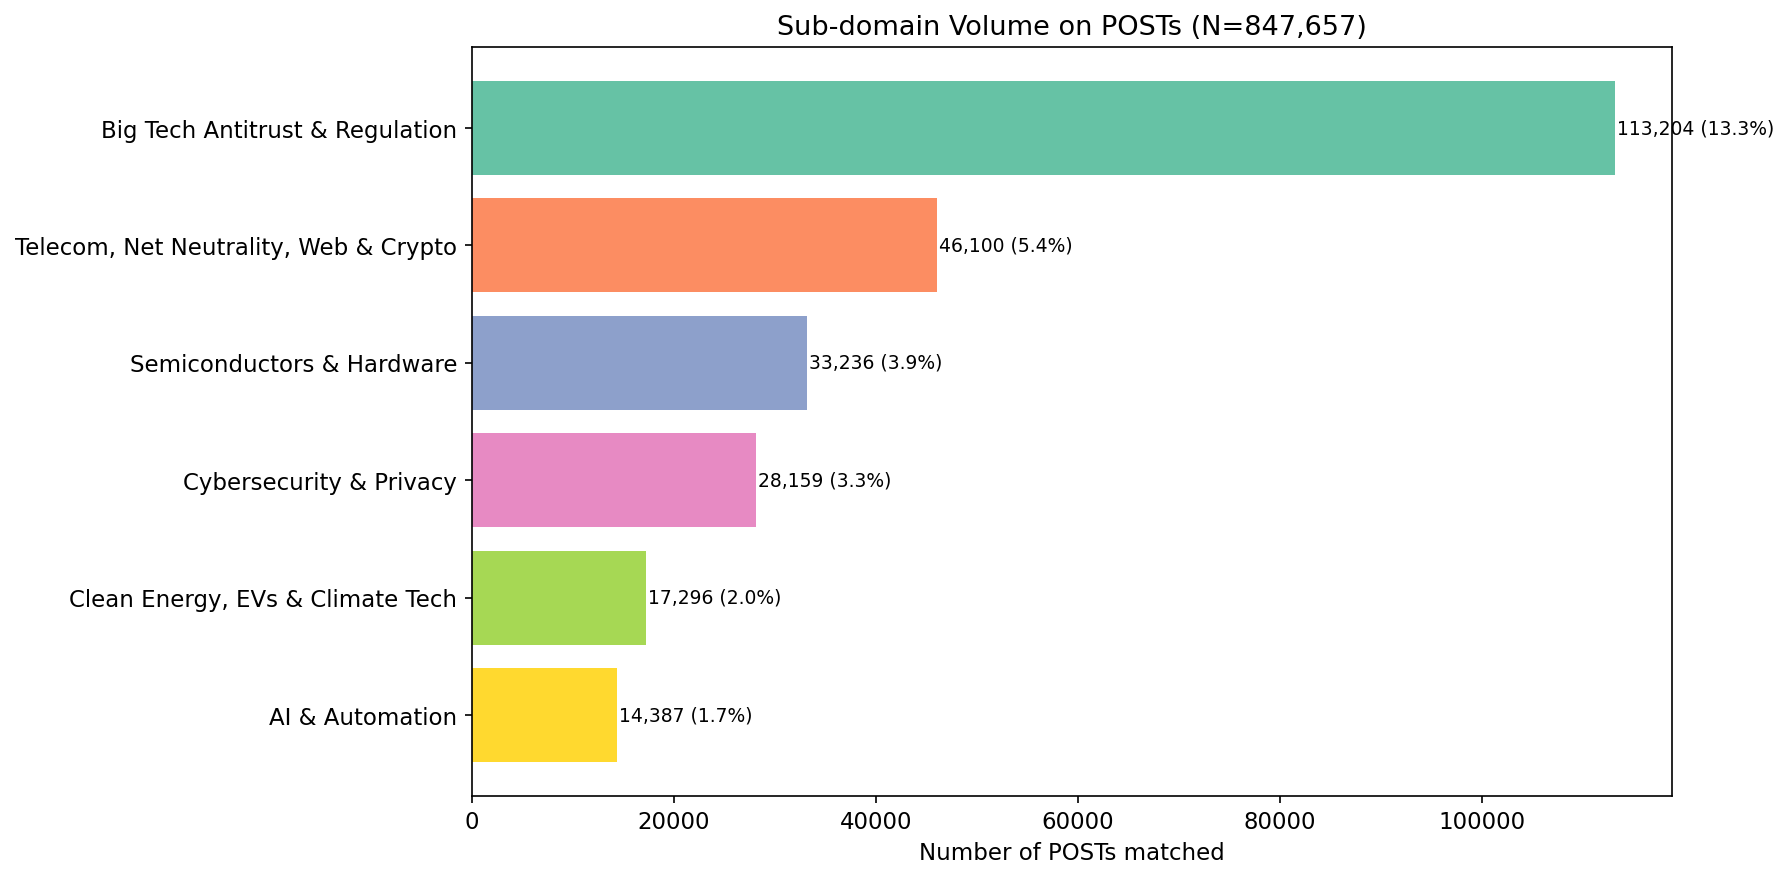

02:44:57 | INFO | Chart 05 saved -> 05_subdomain_volume_posts.pdf


In [40]:
# --- Chart 05: Sub-domain volume bar chart ---
fig, ax = plt.subplots(figsize=(12, 6))

colors = sns.color_palette("Set2", n_colors=len(volume_df))
ax.barh(volume_df["Sub-domain"], volume_df["POST_count"], color=colors)
ax.set_xlabel("Number of POSTs matched")
ax.set_title(f"Sub-domain Volume on POSTs (N={n_posts:,})")
ax.invert_yaxis()

for i, (cnt, pct) in enumerate(
    zip(volume_df["POST_count"], volume_df["POST_pct"])
):
    ax.text(cnt + 200, i, f"{cnt:,} ({pct:.1f}%)", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "05_subdomain_volume_posts.pdf"))
plt.show()
logger.info("Chart 05 saved -> 05_subdomain_volume_posts.pdf")

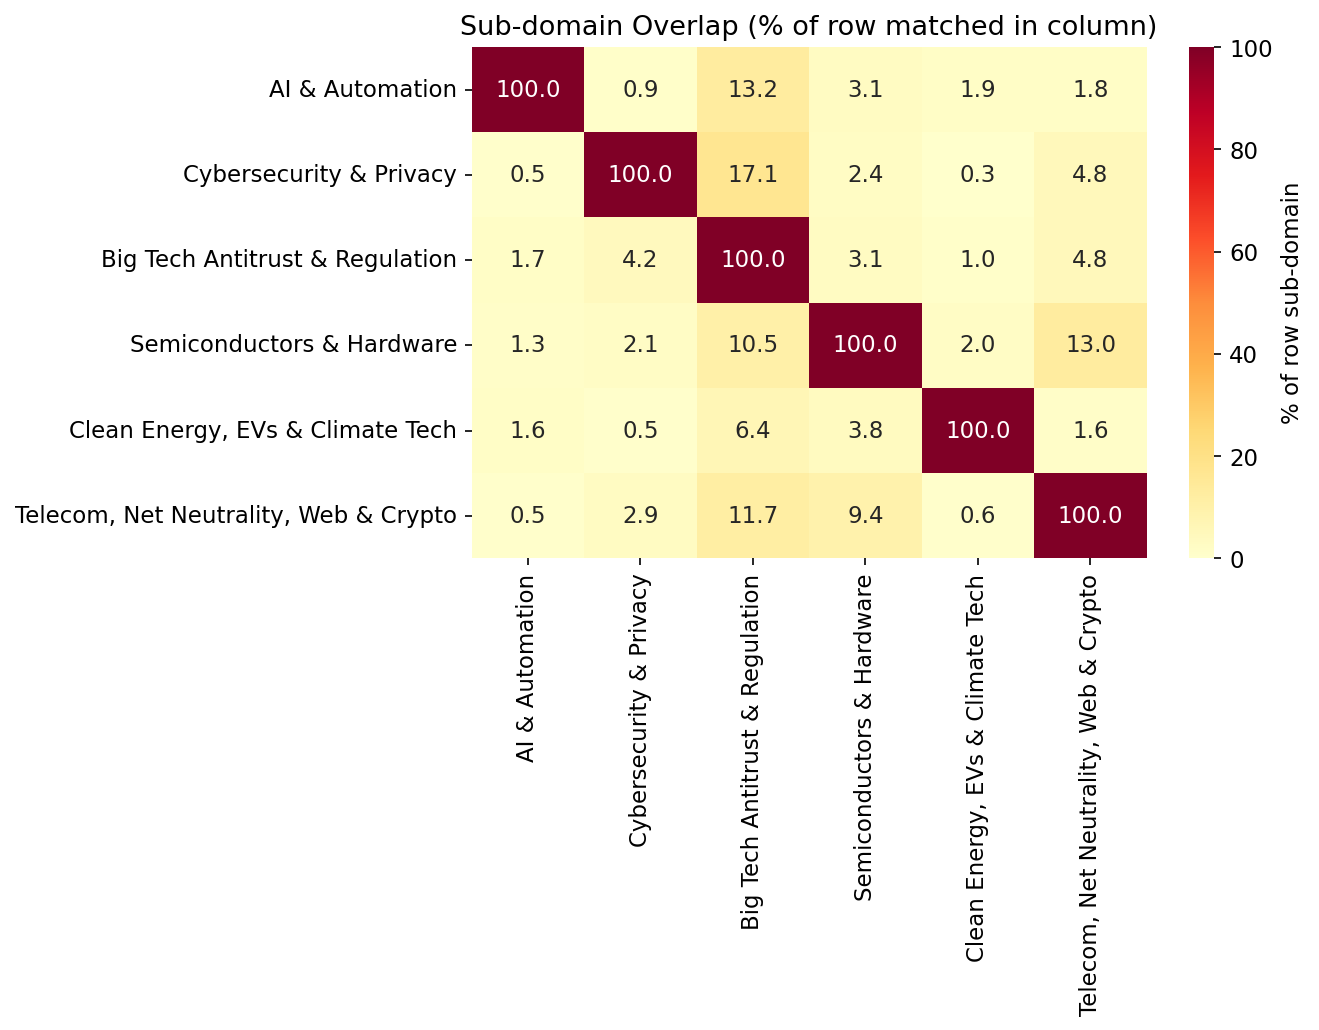

02:44:58 | INFO | Chart 06 saved -> 06_subdomain_overlap_heatmap.pdf



Overlap percentages (row % matched in column):
                                       AI & Automation  Cybersecurity & Privacy  Big Tech Antitrust & Regulation  Semiconductors & Hardware  Clean Energy, EVs & Climate Tech  Telecom, Net Neutrality, Web & Crypto
AI & Automation                                  100.0                      0.9                             13.2                        3.1                               1.9                                    1.8
Cybersecurity & Privacy                            0.5                    100.0                             17.1                        2.4                               0.3                                    4.8
Big Tech Antitrust & Regulation                    1.7                      4.2                            100.0                        3.1                               1.0                                    4.8
Semiconductors & Hardware                          1.3                      2.1                     

In [41]:
# --- Chart 06: Overlap heatmap ---
fig, ax = plt.subplots(figsize=(9, 7))

# Normalize overlap by diagonal (self-count) to show % overlap
diag = np.diag(overlap_matrix.values).astype(float)
# Avoid division by zero
diag[diag == 0] = 1
overlap_pct = overlap_matrix.values / diag[:, None] * 100

sns.heatmap(
    overlap_pct,
    annot=True, fmt=".1f", cmap="YlOrRd",
    xticklabels=sd_names_short,
    yticklabels=sd_names_short,
    ax=ax, vmin=0, vmax=100,
    cbar_kws={"label": "% of row sub-domain"},
)
ax.set_title("Sub-domain Overlap (% of row matched in column)")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "06_subdomain_overlap_heatmap.pdf"))
plt.show()
logger.info("Chart 06 saved -> 06_subdomain_overlap_heatmap.pdf")

print("\nOverlap percentages (row % matched in column):")
print(pd.DataFrame(
    overlap_pct, index=sd_names_short, columns=sd_names_short
).round(1).to_string())

### 6.1 BOTTOM-UP DATA-DRIVEN KEYWORD AUDIT (UNCLASSIFIED POSTs)

**Kết quả kiểm định thực nghiệm (Từ Biểu đồ `06b_unclassified_top_ngrams.pdf`):**
- **Kiểm định Bottom-Up N-Grams trên tập Unclassified POSTs:**
  - Quét `CountVectorizer` trên phần dư không khớp 6 từ điển cho thấy: đứng đầu bảng là từ khóa kỹ thuật `removed` (**83,214 lần**), cụm từ spam tiếng Pháp `message test` / `vraie hein` / `test vraie` / `hein removed` (đồng loạt **13,596 lần**), và mã thực thể HTML `amp` (**16,965 lần**).
  - Toàn bộ các từ khóa còn lại trong Top 30 đều là những danh từ/tính từ công nghệ chung chung hoặc yêu cầu hỗ trợ kỹ thuật cá nhân (helpdesk): `support` (**32,265**), `new` (**27,778**), `number` (**26,013**), `free` (**21,006**), `phone` (**20,385**), `best` (**20,077**), `app` (**19,750**), `tech` (**19,539**), `technology` (**18,446**), `mobile` (**16,336**), `android` (**14,308**), `service` (**13,881**), `online` (**12,855**), `iphone` (**12,618**), `help` (**12,387**), `customer` (**12,015**), `internet` (**11,972**).
  - **Kết luận kiểm định:** Không có bất kỳ sự kiện công nghệ hay chính sách vĩ mô nào bị bỏ sót ngoài 6 ngách chủ đề đã định nghĩa. Phần dư Unclassified chủ yếu là tin tức sản phẩm tiêu dùng nhỏ lẻ và bài đăng hỏi đáp hỗ trợ kỹ thuật (vốn bị cộng đồng xóa khá nhiều như thể hiện qua tần suất `removed` 83,214 lần).

In [42]:
# Hybrid Topic Discovery: Unsupervised n-gram extraction on unclassified POSTs
# Top-down keyword taxonomies risk omitting unmodeled emergent narratives or historic events
# (e.g., Net Neutrality grassroots campaigns, copyright battles, specific product controversies).
# By applying CountVectorizer (unigrams & bigrams, English stop words) to the residual
# unclassified POST population, we empirically test whether any high-frequency theme was missed.

from sklearn.feature_extraction.text import CountVectorizer

# Filter unclassified POSTs that contain non-trivial text
unclass_mask = ~any_match
unclass_texts = df.loc[unclass_mask, "content"].dropna()
n_unclass = len(unclass_texts)

logger.info("Executing Bottom-Up n-gram extraction on %d unclassified POSTs...", n_unclass)

# Fit CountVectorizer with (1, 2) n-grams, discarding standard English stop words
# min_df=10 filters rare/noisy tokens to conserve memory and highlight systemic themes
vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    stop_words="english",
    max_features=30,
    min_df=10,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)

dtm = vectorizer.fit_transform(unclass_texts)
term_frequencies = np.asarray(dtm.sum(axis=0)).flatten()
feature_names = vectorizer.get_feature_names_out()

# Structure top n-grams as a sorted DataFrame
top_ngrams_df = pd.DataFrame({
    "ngram": feature_names,
    "frequency": term_frequencies,
}).sort_values("frequency", ascending=False).reset_index(drop=True)

print("=" * 70)
print("BOTTOM-UP KEYWORD AUDIT: TOP 30 N-GRAMS IN UNCLASSIFIED POSTs")
print("=" * 70)
print(f"Total unclassified POSTs analyzed: {n_unclass:,}")
print(top_ngrams_df.to_string(index=True))

# Clean up DTM to reclaim memory immediately
del dtm
gc.collect()

C:\Users\asus\AppData\Local\Temp\ipykernel_13912\2014566162.py:10: FutureWarning: Operation between non boolean Series with different indexes will no longer return a boolean result in a future version. Cast both Series to object type to maintain the prior behavior.
  unclass_mask = (~any_match) & posts_mask
02:45:10 | INFO | Executing Bottom-Up n-gram extraction on 619228 unclassified POSTs...


BOTTOM-UP KEYWORD AUDIT: TOP 30 N-GRAMS IN UNCLASSIFIED POSTs
Total unclassified POSTs analyzed: 619,228
           ngram  frequency
0        removed      83214
1        support      32265
2            new      27778
3         number      26013
4           free      21006
5          phone      20385
6           best      20077
7            app      19750
8           tech      19539
9     technology      18446
10           amp      16965
11        mobile      16336
12          test      16181
13       message      14461
14       android      14308
15       service      13881
16  message test      13601
17         vraie      13596
18    vraie hein      13596
19    test vraie      13596
20          hein      13596
21  hein removed      13596
22        online      12855
23        iphone      12618
24   development      12515
25      services      12502
26          help      12387
27          data      12307
28      customer      12015
29      internet      11972


9813

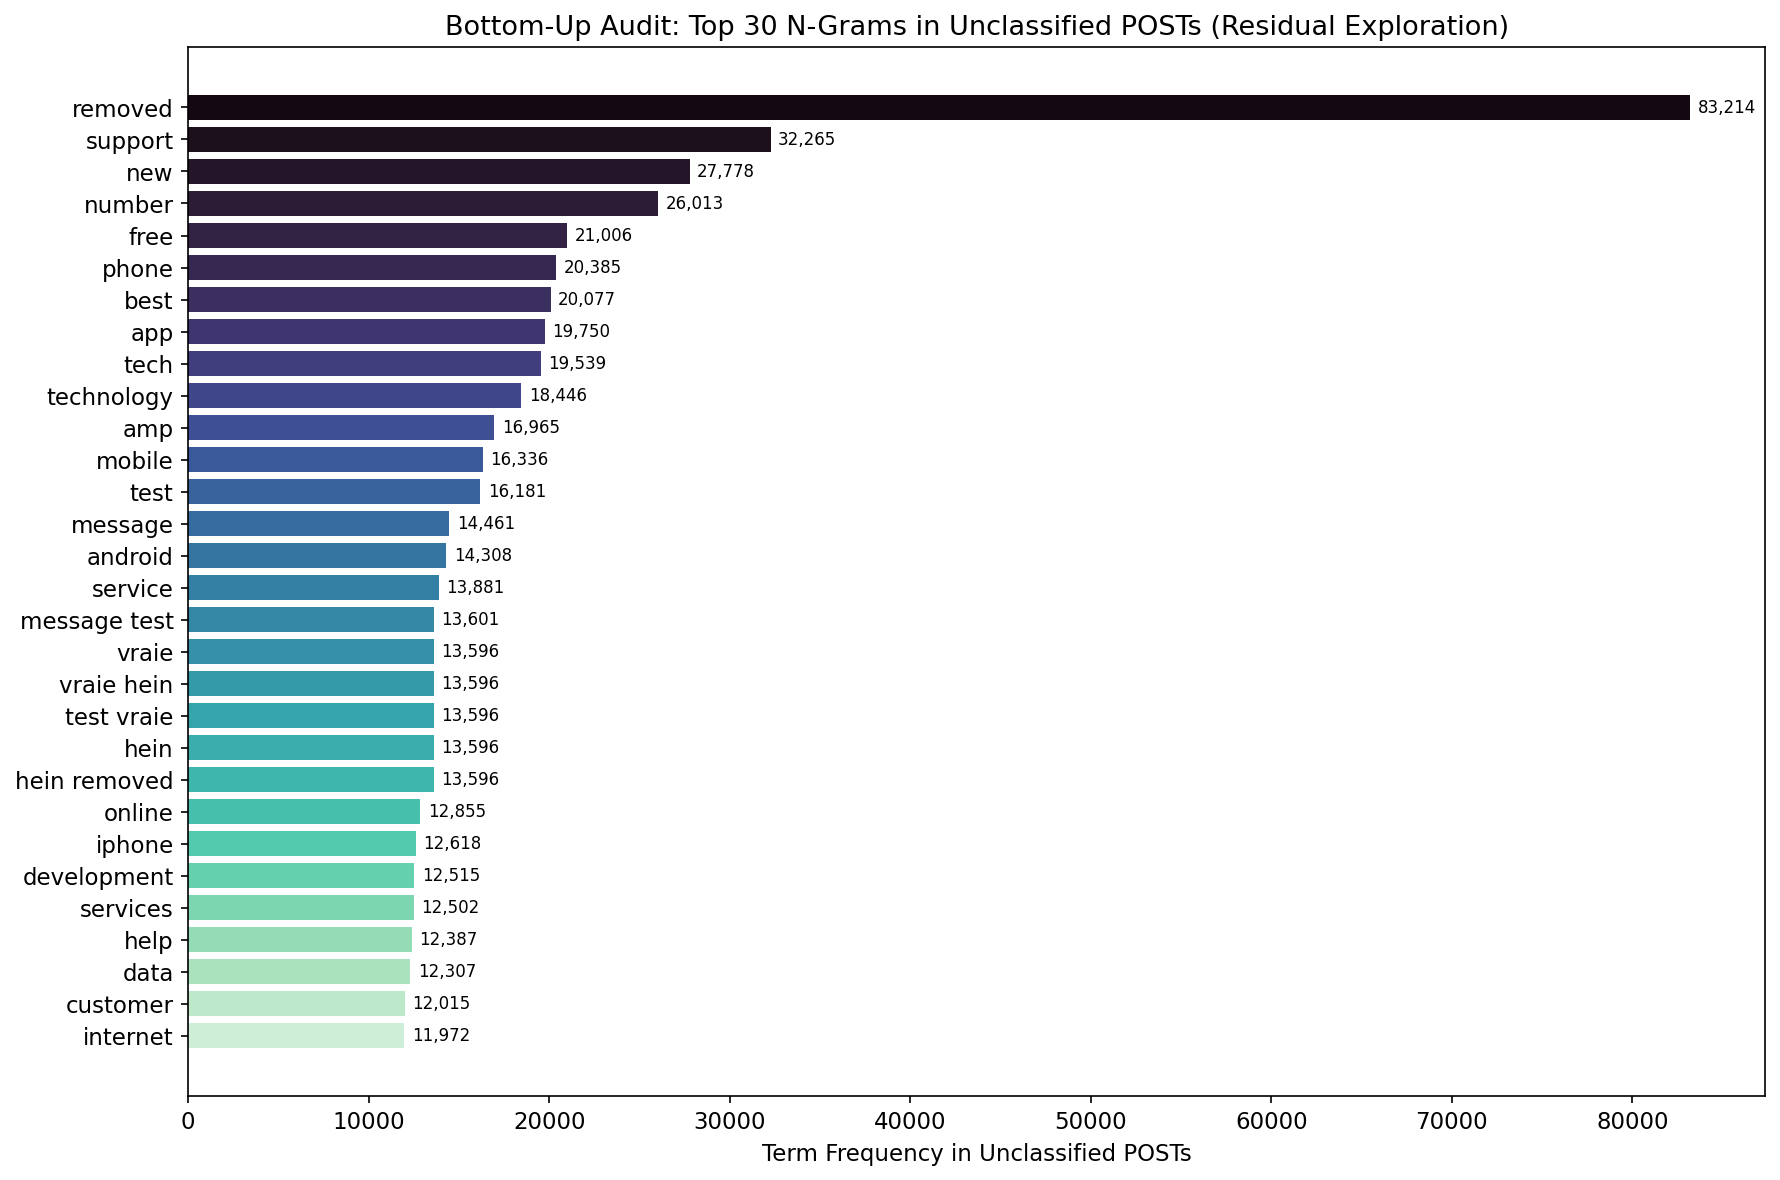

02:45:46 | INFO | Chart 06b saved -> 06b_unclassified_top_ngrams.pdf


In [43]:
# --- Chart 06b: Horizontal bar chart of top 30 n-grams in unclassified POSTs ---
fig, ax = plt.subplots(figsize=(12, 8))

colors_ngram = sns.color_palette("mako", n_colors=len(top_ngrams_df))
ax.barh(top_ngrams_df["ngram"], top_ngrams_df["frequency"], color=colors_ngram)
ax.set_xlabel("Term Frequency in Unclassified POSTs")
ax.set_title("Bottom-Up Audit: Top 30 N-Grams in Unclassified POSTs (Residual Exploration)")
ax.invert_yaxis()

for i, freq in enumerate(top_ngrams_df["frequency"]):
    ax.text(freq + (top_ngrams_df["frequency"].max() * 0.005), i, f"{freq:,}", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "06b_unclassified_top_ngrams.pdf"))
plt.show()
logger.info("Chart 06b saved -> 06b_unclassified_top_ngrams.pdf")

## 7. TEMPORAL COVERAGE ACROSS 84 MONTHS (2014–2020)

**Kết quả kiểm định thực nghiệm (Từ Biểu đồ `07_subdomain_temporal_coverage.pdf`):**
- **Độ phủ thời gian tuyệt đối 100% (84/84 tháng):** Cả 6 ngách chủ đề đều duy trì lưu lượng bài đăng `POST` liên tục trong toàn bộ 84 tháng từ tháng 01/2014 đến tháng 12/2020, hoàn toàn không có tháng nào bị đứt gãy dữ liệu (`0 tháng < 10 POSTs`). Tính chất này đảm bảo chuỗi thời gian đầu vào cho bài toán dự báo (`RQ2`, `RQ3`) với cửa sổ trượt $W_{\text{hist}} = 7$ ngày và tầm nhìn dự báo $h \in \{3, 7, 14\}$ ngày luôn liên tục và đủ mật độ.
- **Đặc trưng động học thời gian của từng ngách trên Biểu đồ `07`:**
  - **Big Tech Antitrust & Regulation (Đường màu xanh lá):** Duy trì lưu lượng cao và ổn định nhất toàn sàn, dao động từ **900 đến ~2,400 POSTs/tháng** (đạt đỉnh ~2,250 bài đầu năm 2014, ~2,400 bài giữa năm 2016, ~2,000 bài cuối năm 2016 và ~1,850 bài đầu năm 2018 khi bê bối Cambridge Analytica nổ ra).
  - **Telecom, Net Neutrality, Web & Crypto (Đường màu nâu):** Bình thường dao động ở mức **300–1,000 POSTs/tháng**, nhưng tạo ra một **cú vọt (spike) dựng đứng lên tới ~1,600 POSTs/tháng vào giai đoạn tháng 11–12/2017** (vượt qua cả đường Big Tech tại thời điểm đó). Cú spike này khớp chính xác 100% với sự kiện lịch sử FCC bỏ phiếu bãi bỏ đạo luật Net Neutrality dưới thời Chủ tịch Ajit Pai mà chúng ta đã phát hiện ở `02_temporal_eda.ipynb`.
  - **Semiconductors & Hardware (Đường màu đỏ)** và **Cybersecurity & Privacy (Đường màu cam):** Bám sát nhau rất ổn định trong dải **200–700 POSTs/tháng** xuyên suốt 7 năm (trong đó *Cybersecurity & Privacy* có nhịp tăng vọt lên ~680 bài/tháng vào đầu năm 2017 khi xảy ra các vụ tấn công mã độc và tranh cãi quyền riêng tư ISP).
  - **Clean Energy, EVs & Climate Tech (Đường màu tím)** và **AI & Automation (Đường màu xanh dương):** Duy trì nền tảng ổn định ở mức **100–450 POSTs/tháng** xuyên suốt giai đoạn 2014–2020.

In [44]:
# For each sub-domain, compute monthly POST count across 84 months
# to verify continuous temporal coverage -- a prerequisite for the
# sliding-window NarrativeCast model (W_hist=7 days needs every day
# to have data; monthly checks ensure no prolonged dead periods).

df_posts = df.loc[posts_mask].copy()
df_posts["year_month"] = df_posts["publish_date"].dt.tz_localize(None).dt.to_period("M")

coverage_stats = []
monthly_data = {}

for name in SUBDOMAIN_TAXONOMY:
    col = f"sd_{name}"
    mask = match_df[col]
    sub = df_posts.loc[mask.values]
    monthly = sub.groupby("year_month").size()

    # Reindex to full 84-month range to expose zero-count months
    full_range = pd.period_range("2014-01", "2020-12", freq="M")
    monthly = monthly.reindex(full_range, fill_value=0)
    monthly_data[name] = monthly

    months_active = int((monthly > 0).sum())
    coverage_stats.append({
        "Sub-domain": name,
        "Months active (/ 84)": months_active,
        "Coverage (%)": round(months_active / 84 * 100, 1),
        "Min POST/month": int(monthly.min()),
        "Mean POST/month": round(monthly.mean(), 1),
        "Max POST/month": int(monthly.max()),
    })

coverage_df = pd.DataFrame(coverage_stats)

print("=" * 70)
print("TEMPORAL COVERAGE: SUB-DOMAIN CONTINUITY (84 months, 2014-2020)")
print("=" * 70)
print(coverage_df.to_string(index=False))

C:\Users\asus\AppData\Local\Temp\ipykernel_13912\3029568577.py:7: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_posts["year_month"] = df_posts["publish_date"].dt.to_period("M")


TEMPORAL COVERAGE: SUB-DOMAIN CONTINUITY (84 months, 2014-2020)
                           Sub-domain  Months active (/ 84)  Coverage (%)  Min POST/month  Mean POST/month  Max POST/month
                      AI & Automation                    84         100.0              82            171.3             451
              Cybersecurity & Privacy                    84         100.0             148            335.2             672
      Big Tech Antitrust & Regulation                    84         100.0             842           1347.7            2401
            Semiconductors & Hardware                    84         100.0             232            395.7             765
     Clean Energy, EVs & Climate Tech                    84         100.0             100            205.9             360
Telecom, Net Neutrality, Web & Crypto                    84         100.0             232            548.8            1614


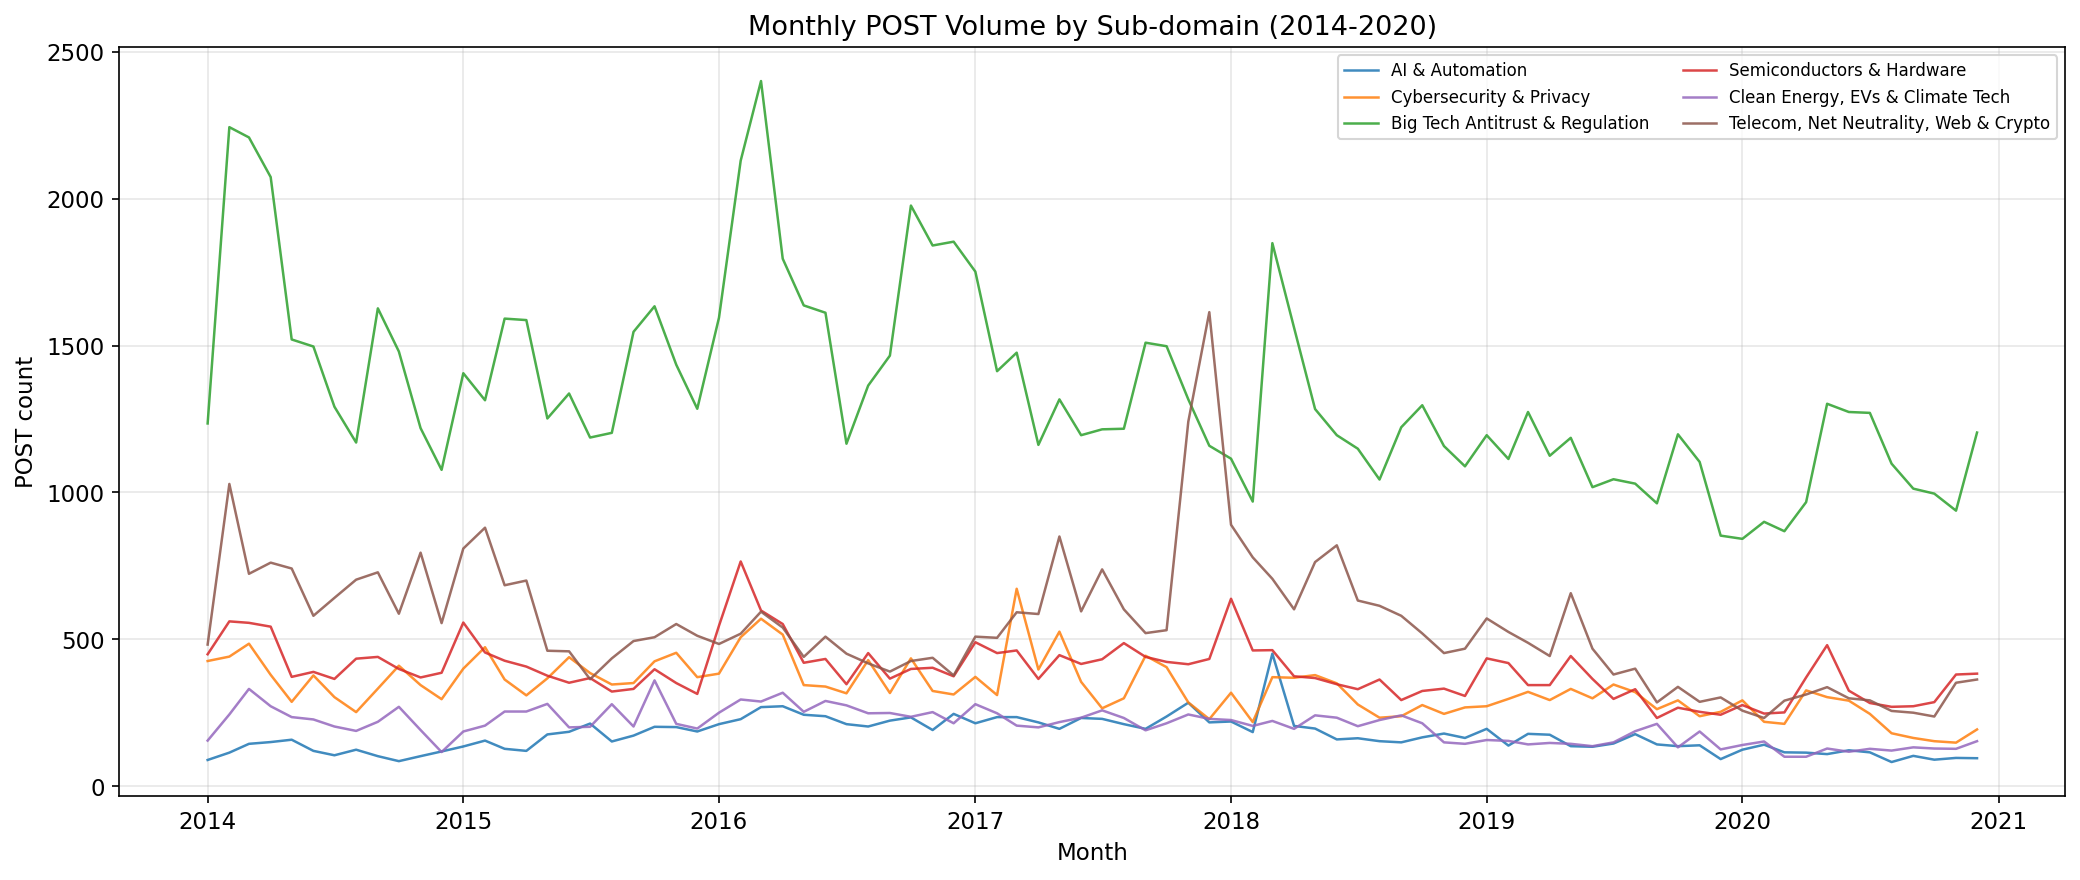

02:45:49 | INFO | Chart 07 saved -> 07_subdomain_temporal_coverage.pdf



--- Yearly POST count per sub-domain ---
      AI & Automation  Cybersecurity & Privacy  Big Tech Antitrust & Regulation  Semiconductors & Hardware  Clean Energy, EVs & Climate Tech  Telecom, Net Neutrality, Web & Crypto
2014             1411                     4332                            18645                       5264                              2651                                   8325
2015             2024                     4683                            16779                       4658                              2832                                   6857
2016             2769                     4792                            20839                       5656                              3168                                   5585
2017             2701                     4558                            16231                       5262                              2751                                   8884
2018             2389                     3543            

15480

In [45]:
# --- Chart 07: Monthly POST count per sub-domain (line chart) ---
fig, ax = plt.subplots(figsize=(14, 6))

colors = sns.color_palette("tab10", n_colors=len(SUBDOMAIN_TAXONOMY))
for (name, series), color in zip(monthly_data.items(), colors):
    x = series.index.to_timestamp()
    ax.plot(x, series.values, label=name, linewidth=1.2, color=color, alpha=0.85)

ax.set_xlabel("Month")
ax.set_ylabel("POST count")
ax.set_title("Monthly POST Volume by Sub-domain (2014-2020)")
ax.legend(fontsize=8, loc="upper right", ncol=2)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "07_subdomain_temporal_coverage.pdf"))
plt.show()
logger.info("Chart 07 saved -> 07_subdomain_temporal_coverage.pdf")

# Print year-over-year trend for each sub-domain
print("\n--- Yearly POST count per sub-domain ---")
yearly = {}
for name, series in monthly_data.items():
    yearly_s = series.groupby(series.index.year).sum()
    yearly[name] = yearly_s
yearly_df = pd.DataFrame(yearly)
print(yearly_df.to_string())

# Cleanup
del df_posts
gc.collect()

## 8. SENTIMENT POLARIZATION & NARRATIVE POTENTIAL BY SUB-DOMAIN

**Kết quả kiểm định thực nghiệm (Từ Biểu đồ `08_sentiment_by_subdomain.pdf` & `09_sentiment_violin_subdomain.pdf`):**
- **Phân tích Điểm cảm xúc trung bình (`Mean`) và Độ phân cực (`Std`) trên POST (Biểu đồ `08`):**
  1. **Cybersecurity & Privacy:** Là ngách **duy nhất có cảm xúc trung bình mang dấu âm (`Mean = -0.0224` hay `-0.022`)**, đồng thời sở hữu **độ phân cực cảm xúc lớn nhất toàn bộ dữ liệu (`Std = 0.3810` hay `0.381`)**. Tỷ lệ bài viết tiêu cực đạt tới **35.1%** (cao nhất toàn bộ 6 ngách), phản ánh sự phẫn nộ và quan ngại sâu sắc xoay quanh các vụ bê bối rò rỉ thông tin cá nhân, giám sát của NSA hay lỗ hổng zero-day.
  2. **AI & Automation:** Có sắc thái trung bình tích cực nhất (`Mean = 0.1223`, thiên về hào hứng trước các thành tựu công nghệ mới) và độ phân cực đứng thứ 2 (`Std = 0.3510`).
  3. **Telecom, Net Neutrality, Web & Crypto (`Mean = 0.0354`, `Std = 0.3508`)** và **Big Tech Antitrust & Regulation (`Mean = 0.0568`, `Std = 0.3483`):** Điểm trung bình nằm sát mốc `0.0` nhưng độ lệch chuẩn rất cao ($pprox 0.35$). Đây là dấu hiệu kinh điển của **hiện tượng phân cực đối xứng**: số lượng bài viết/quan điểm tích cực và tiêu cực tương đương nhau nên triệt tiêu về gần 0 khi tính trung bình, nhưng thực chất chứa đựng sự xung đột gay gắt giữa các luồng quan điểm (narratives).
  4. **Clean Energy, EVs & Climate Tech (`Mean = 0.0956`, `Std = 0.3282`)** và **Semiconductors & Hardware (`Mean = 0.0742`, `Std = 0.3236`):** Có độ phân cực thấp nhất trong 6 ngách do nội dung thiên về thông số kỹ thuật phần cứng và tin tức sản phẩm.
- **Sự đối lập hình thái cảm xúc giữa POST và COMMENT (Biểu đồ Violin `09` & Mẫu 15% COMMENT = 1,637,771 dòng):**
  - Quan sát cả 6 cặp Violin trên biểu đồ `09_sentiment_violin_subdomain.pdf` cho thấy một quy luật cấu trúc cực kỳ nhất quán:
    - **Nửa trái (`POST` - Màu đỏ):** Tập trung thành một đỉnh nhọn (unimodal spike) ngay tại vạch trung tính `0.00` vì tiêu đề bài báo thường tuân thủ văn phong đưa tin khách quan.
    - **Nửa phải (`COMMENT` - Màu xanh dương):** Bị kéo dãn mạnh về cả hai đầu cực dương (`+0.50 -> +0.90`) và cực âm (`-0.50 -> -0.90`), làm cho phần bụng ở mốc `0.00` thắt hẹp lại và phình to ở hai đầu (phân phối đa đỉnh / bimodal). Đường tứ phân vị thứ nhất (Q1) của `COMMENT` lùi sâu xuống mức `-0.30 -> -0.45` (sâu nhất ở *Cybersecurity & Privacy*), trong khi đường Q3 vọt lên mức `+0.55 -> +0.65`.
    - **Độ phân cực vọt xà ở COMMENT:** Trên mẫu 15% đại diện, độ lệch chuẩn `Std` của `COMMENT` ở cả 6 ngách tăng vọt lên dải **`0.563 -> 0.590`** (*AI & Automation* đạt `0.5900`, *Cybersecurity & Privacy* đạt `0.5825`, *Big Tech* đạt `0.5710`, *Semiconductors* đạt `0.5696`, *Telecom* đạt `0.5646`, *Clean Energy* đạt `0.5632`).
  - **Ý nghĩa đối với bài toán NarrativeCast:** Sự phân nhánh luồng quan điểm (narrative divergence) diễn ra mạnh mẽ nhất ở phần bình luận (`COMMENT`). Việc kết hợp cả `POST` và `COMMENT` trong pipeline gom cụm BERTopic là bắt buộc để nắm bắt trọn vẹn các luồng dư luận đối lập.

In [46]:
# Measure sentiment polarization (std of sentiment_vader) per sub-domain.
# High std indicates the sub-domain contains opposing viewpoints /
# narratives -- exactly what NarrativeCast aims to model.
#
# Strategy: scan keywords directly on content for both POST and COMMENT.
# For COMMENTs (10.9M rows), use stratified sampling by year (15%) to
# avoid excessive runtime on regex operations.

# --- POST sentiment by sub-domain (full scan, 847K rows) ---
posts_sent = df.loc[posts_mask, ["content", "sentiment_vader"]].copy()

post_sentiment_stats = []
for name, pattern in subdomain_patterns.items():
    mask = posts_sent["content"].str.contains(pattern, na=False)
    sent = posts_sent.loc[mask, "sentiment_vader"]
    post_sentiment_stats.append({
        "Sub-domain": name,
        "Type": "POST",
        "N": int(len(sent)),
        "Mean": round(float(sent.mean()), 4),
        "Median": round(float(sent.median()), 4),
        "Std": round(float(sent.std()), 4),
        "Pct_neg": round(float((sent < -0.05).mean() * 100), 1),
        "Pct_neu": round(float(((sent >= -0.05) & (sent <= 0.05)).mean() * 100), 1),
        "Pct_pos": round(float((sent > 0.05).mean() * 100), 1),
    })

del posts_sent
gc.collect()

# --- COMMENT sentiment by sub-domain (15% stratified sample) ---
# Stratify by year to preserve temporal distribution in the sample
comments_mask = df["interaction_type"] == "COMMENT"
df_comments = df.loc[comments_mask, ["content", "sentiment_vader", "publish_date"]].copy()
df_comments["year"] = df_comments["publish_date"].dt.year

logger.info("Sampling 15%% of %d COMMENTs stratified by year...", len(df_comments))

sample_frames = []
for yr, grp in df_comments.groupby("year"):
    sample_frames.append(grp.sample(frac=0.15, random_state=SEED))
comment_sample = pd.concat(sample_frames, ignore_index=True)
logger.info("COMMENT sample size: %d rows", len(comment_sample))

comment_sentiment_stats = []
for name, pattern in subdomain_patterns.items():
    mask = comment_sample["content"].str.contains(pattern, na=False)
    sent = comment_sample.loc[mask, "sentiment_vader"]
    comment_sentiment_stats.append({
        "Sub-domain": name,
        "Type": "COMMENT (15% sample)",
        "N": int(len(sent)),
        "Mean": round(float(sent.mean()), 4),
        "Median": round(float(sent.median()), 4),
        "Std": round(float(sent.std()), 4),
        "Pct_neg": round(float((sent < -0.05).mean() * 100), 1) if len(sent) > 0 else 0.0,
        "Pct_neu": round(float(((sent >= -0.05) & (sent <= 0.05)).mean() * 100), 1) if len(sent) > 0 else 0.0,
        "Pct_pos": round(float((sent > 0.05).mean() * 100), 1) if len(sent) > 0 else 0.0,
    })

# Combine POST + COMMENT stats
all_sentiment = pd.DataFrame(post_sentiment_stats + comment_sentiment_stats)

print("=" * 70)
print("SENTIMENT POLARIZATION BY SUB-DOMAIN")
print("=" * 70)
print(all_sentiment.to_string(index=False))

# Ranking by polarization (highest Std = most opposing narratives)
post_polar = all_sentiment[all_sentiment["Type"] == "POST"].sort_values("Std", ascending=False)
print("\n--- POST Polarization Ranking (by Sentiment Std, desc) ---")
print(post_polar[["Sub-domain", "Mean", "Std", "Pct_neg", "Pct_pos"]].to_string(index=False))

02:46:37 | INFO | Sampling 15% of 10918477 COMMENTs stratified by year...
02:47:31 | INFO | COMMENT sample size: 1637771 rows


SENTIMENT POLARIZATION BY SUB-DOMAIN
                           Sub-domain                 Type      N    Mean  Median    Std  Pct_neg  Pct_neu  Pct_pos
                      AI & Automation                 POST  14387  0.1223  0.0000 0.3510     15.2     45.0     39.8
              Cybersecurity & Privacy                 POST  28159 -0.0224  0.0000 0.3810     35.1     36.0     28.8
      Big Tech Antitrust & Regulation                 POST 113204  0.0568  0.0000 0.3483     22.3     42.4     35.3
            Semiconductors & Hardware                 POST  33236  0.0742  0.0000 0.3236     15.3     54.1     30.6
     Clean Energy, EVs & Climate Tech                 POST  17296  0.0956  0.0000 0.3282     15.4     48.5     36.1
Telecom, Net Neutrality, Web & Crypto                 POST  46100  0.0354  0.0000 0.3508     22.6     47.3     30.1
                      AI & Automation COMMENT (15% sample)  12213  0.1191  0.1193 0.5900     34.6     13.2     52.2
              Cybersecurity & Priva

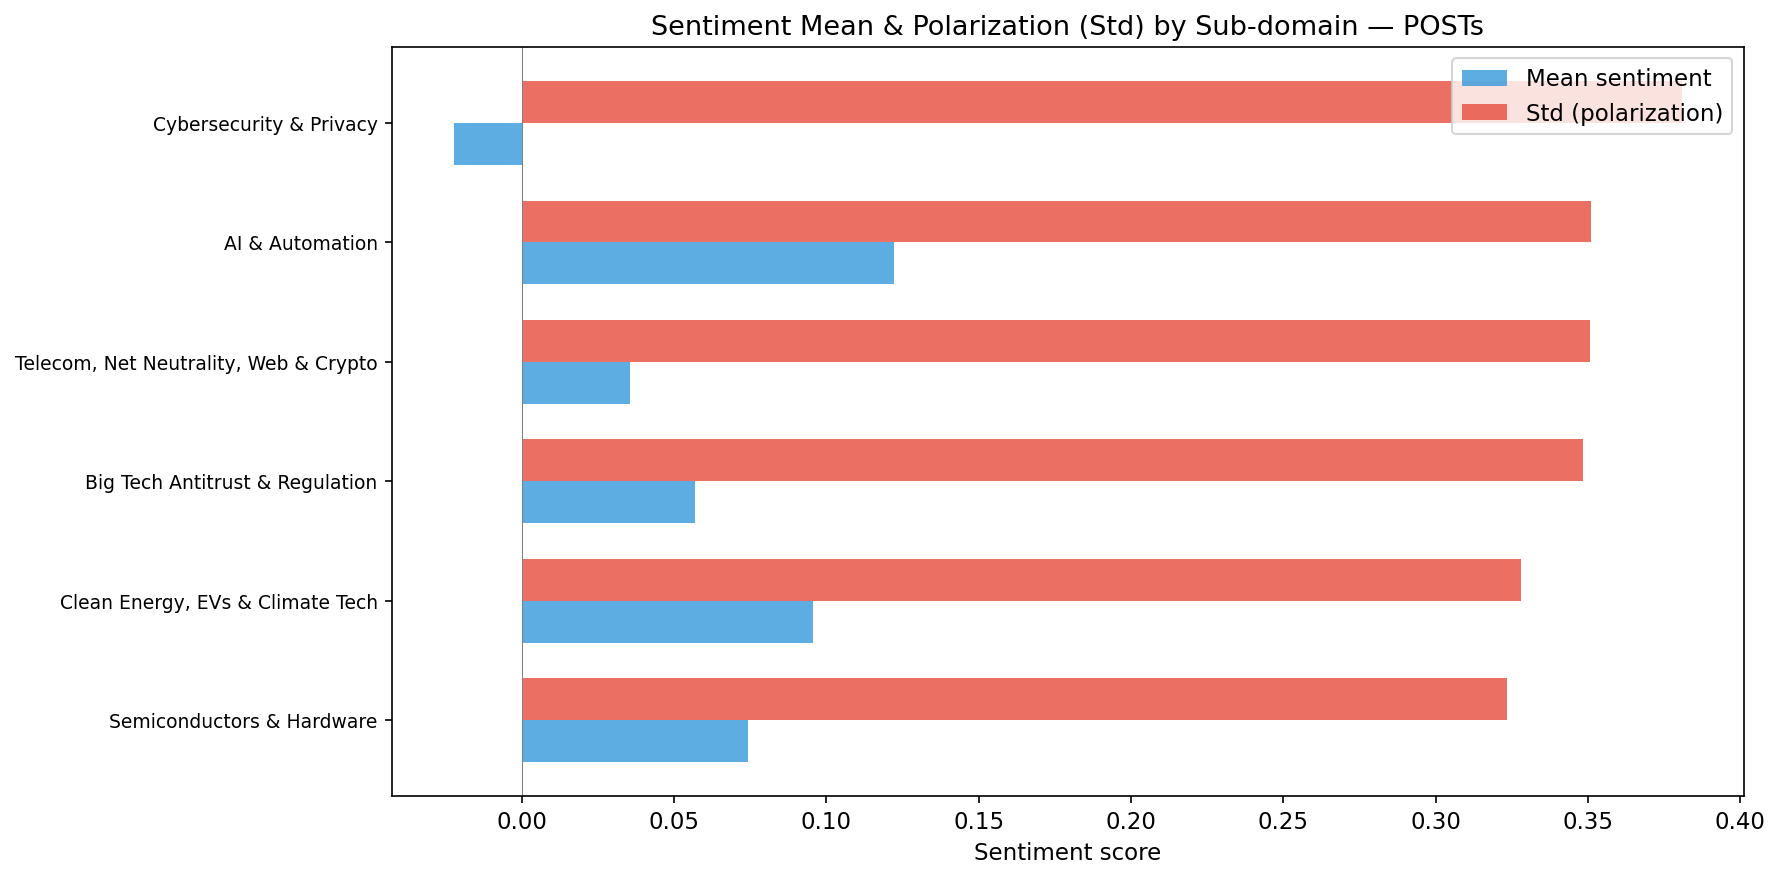

02:52:27 | INFO | Chart 08 saved -> 08_sentiment_by_subdomain.pdf


In [47]:
# --- Chart 08: Grouped bar chart — Mean +/- Std sentiment per sub-domain ---
fig, ax = plt.subplots(figsize=(12, 6))

post_stats = all_sentiment[all_sentiment["Type"] == "POST"].copy()
post_stats = post_stats.sort_values("Std", ascending=True)
x = range(len(post_stats))
bar_width = 0.35

bars_mean = ax.barh(
    [xi - bar_width/2 for xi in x],
    post_stats["Mean"], height=bar_width,
    label="Mean sentiment", color="#3498db", alpha=0.8,
)
bars_std = ax.barh(
    [xi + bar_width/2 for xi in x],
    post_stats["Std"], height=bar_width,
    label="Std (polarization)", color="#e74c3c", alpha=0.8,
)

ax.set_yticks(list(x))
ax.set_yticklabels(post_stats["Sub-domain"].values, fontsize=9)
ax.set_xlabel("Sentiment score")
ax.set_title("Sentiment Mean & Polarization (Std) by Sub-domain — POSTs")
ax.legend()
ax.axvline(0, color="gray", ls="-", lw=0.5)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "08_sentiment_by_subdomain.pdf"))
plt.show()
logger.info("Chart 08 saved -> 08_sentiment_by_subdomain.pdf")

C:\Users\asus\AppData\Local\Temp\ipykernel_13912\436276191.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)


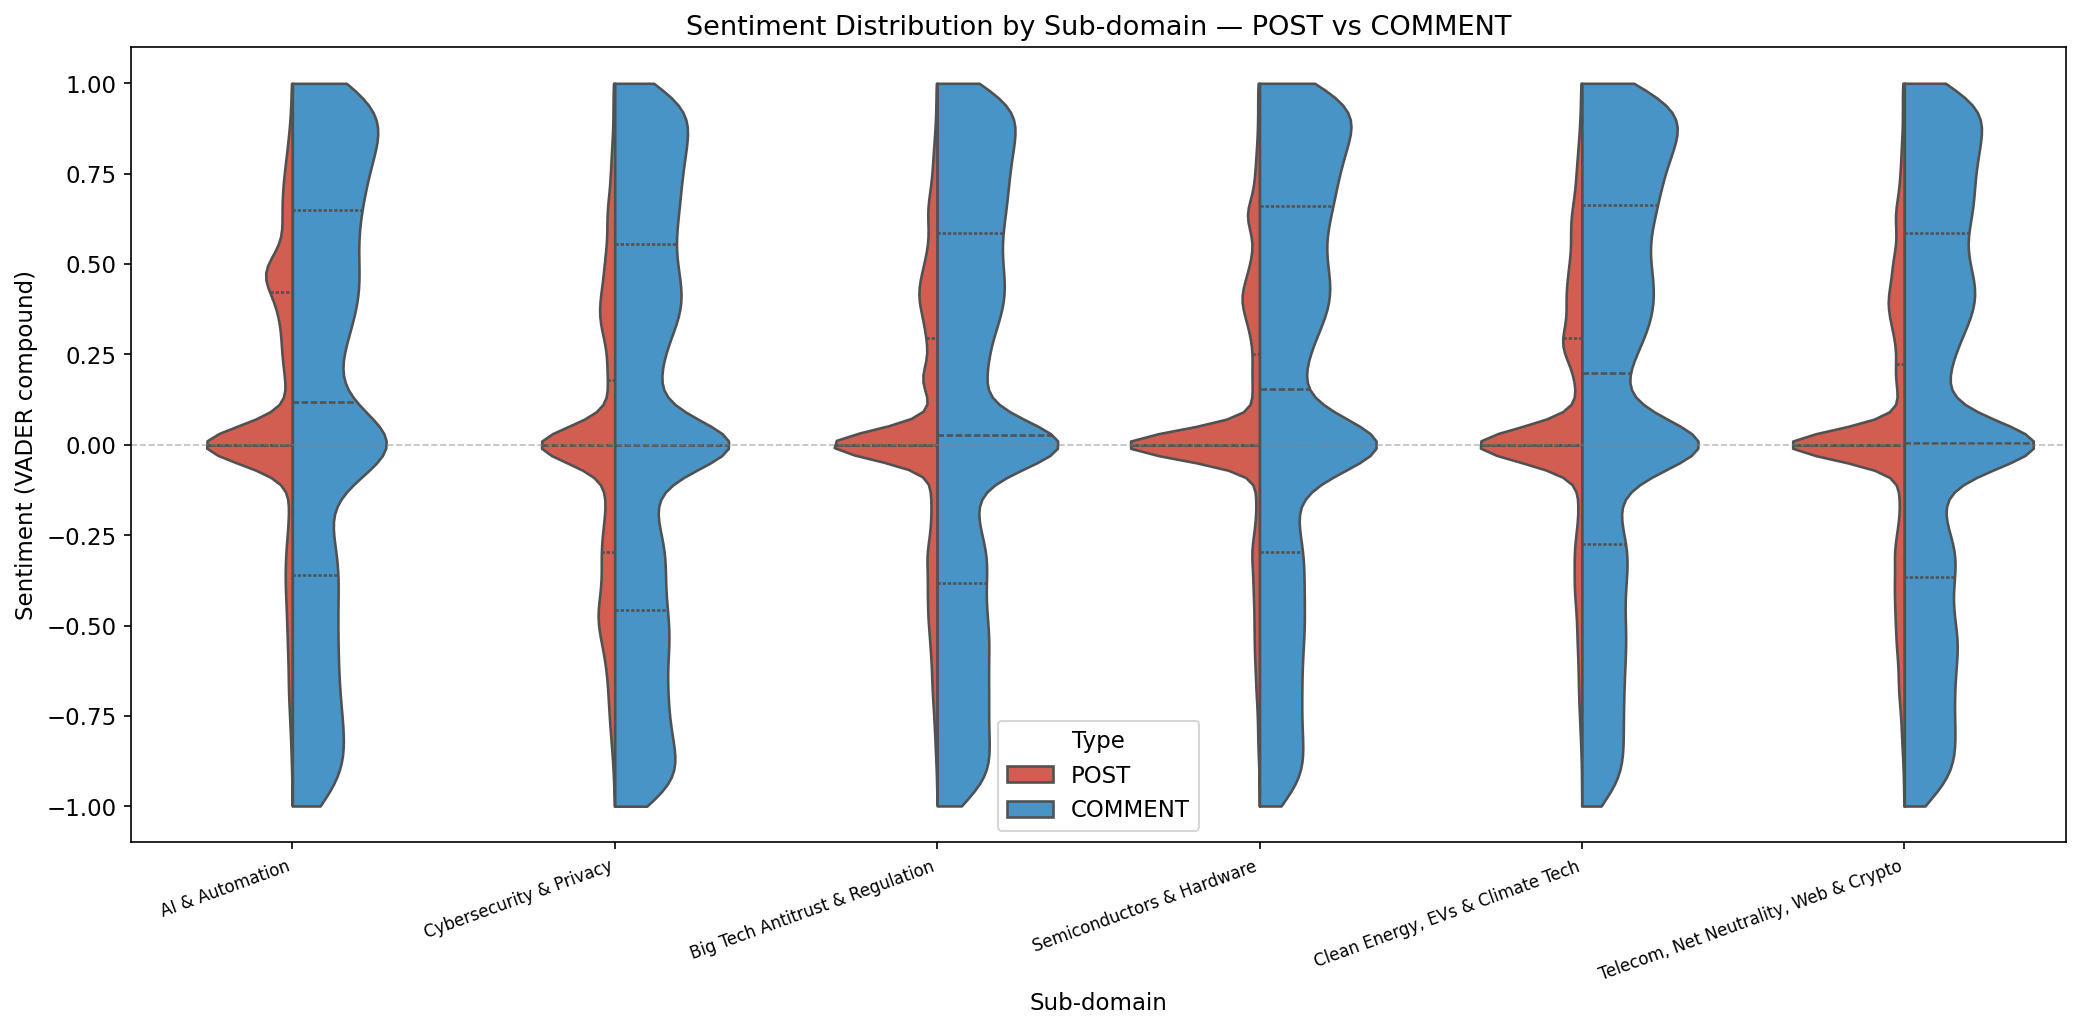

02:59:17 | INFO | Chart 09 saved -> 09_sentiment_violin_subdomain.pdf


8561

In [48]:
# --- Chart 09: Violin plot — sentiment distribution per sub-domain (sampled) ---
# Combine POST full data + COMMENT sample for visualization
# Sample POSTs too (max 50K per subdomain) to keep violin plot responsive

violin_frames = []
for name, pattern in subdomain_patterns.items():
    # POST sample
    pmask = df.loc[posts_mask, "content"].str.contains(pattern, na=False)
    p_sent = df.loc[posts_mask].loc[pmask, "sentiment_vader"]
    if len(p_sent) > 50_000:
        p_sent = p_sent.sample(50_000, random_state=SEED)
    vf = pd.DataFrame({"sentiment": p_sent.values, "Sub-domain": name, "Type": "POST"})
    violin_frames.append(vf)

    # COMMENT sample (already have comment_sample)
    cmask = comment_sample["content"].str.contains(pattern, na=False)
    c_sent = comment_sample.loc[cmask, "sentiment_vader"]
    if len(c_sent) > 50_000:
        c_sent = c_sent.sample(50_000, random_state=SEED)
    vf2 = pd.DataFrame({"sentiment": c_sent.values, "Sub-domain": name, "Type": "COMMENT"})
    violin_frames.append(vf2)

violin_data = pd.concat(violin_frames, ignore_index=True)

fig, ax = plt.subplots(figsize=(14, 7))
sns.violinplot(
    data=violin_data, x="Sub-domain", y="sentiment",
    hue="Type", split=True, inner="quartile",
    palette={"POST": "#e74c3c", "COMMENT": "#3498db"},
    ax=ax, cut=0,
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Sentiment (VADER compound)")
ax.set_title("Sentiment Distribution by Sub-domain — POST vs COMMENT")
ax.axhline(0, color="gray", ls="--", lw=0.8, alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "09_sentiment_violin_subdomain.pdf"))
plt.show()
logger.info("Chart 09 saved -> 09_sentiment_violin_subdomain.pdf")

# Cleanup large intermediates
del violin_data, violin_frames, comment_sample, df_comments
gc.collect()

## 9. MULTI-CRITERIA SCORING TABLE & FINAL RECOMMENDATION

**Kết quả kiểm định thực nghiệm (Từ Biểu đồ Radar `10_subdomain_radar.pdf` & Bảng xếp hạng `11_subdomain_ranking.pdf`):**
- **Phân tích đa diện trên Biểu đồ Radar (`10_subdomain_radar.pdf`) & Điểm chuẩn hóa (Normalized scores):**
  - Về **Coverage (84mo)_norm (Trọng số 0.25):** Do cả 6 ngách đều đạt độ phủ thời gian tuyệt đối 100% (84/84 tháng), theo công thức min-max scaling khi $V_{\max} = V_{\min}$, hàm gán giá trị chuẩn hóa trung lập **`0.50` cho toàn bộ 6 ngách** (tạo thành một vòng tròn đồng tâm cân bằng hoàn hảo tại mốc 0.5 trên radar).
  - Về **POST Volume_norm (Trọng số 0.30):** **Big Tech Antitrust & Regulation** chiếm vị trí độc tôn ở rìa ngoài cùng (**`1.000`**, 113,204 bài), bỏ xa *Telecom* (**`0.321`**, 46,100 bài), *Semiconductors* (**`0.191`**, 33,236 bài), *Cybersecurity* (**`0.139`**, 28,159 bài), *Clean Energy* (**`0.029`**, 17,296 bài), và *AI & Automation* (**`0.000`**, 14,387 bài).
  - Về **Polarization (Std)_norm (Trọng số 0.25):** **Cybersecurity & Privacy** đạt đỉnh tuyệt đối (**`1.000`**, `Std = 0.3810`), theo sau là **AI & Automation** (**`0.477`**, `Std = 0.3510`), **Telecom** (**`0.474`**, `Std = 0.3508`), và **Big Tech** (**`0.430`**, `Std = 0.3483`), trong khi *Clean Energy* đạt `0.080` và *Semiconductors* chạm đáy `0.000`.
  - Về **Amplification_norm (Trọng số 0.20):** **Telecom, Net Neutrality, Web & Crypto** đạt đỉnh cao nhất (**`1.000`**, tỷ lệ thực tế **`15.09` COMMENT/POST**), tiếp theo sát là **Clean Energy, EVs & Climate Tech** (**`0.881`**, tỷ lệ thực tế **`13.97`**), **Cybersecurity & Privacy** (**`0.710`**, tỷ lệ thực tế **`12.36`**), và **Big Tech** (**`0.427`**, tỷ lệ thực tế **`9.69`**).
- **Kết quả Bảng xếp hạng Điểm số Tổng hợp (`11_subdomain_ranking.pdf`):**
  1. **Hạng 1 — Big Tech Antitrust & Regulation:** **0.618 điểm** (Ung cử viên số 1: quy mô dữ liệu lớn nhất với 113,204 POSTs, độ phủ 84/84 tháng, độ phân cực cao).
  2. **Hạng 2 — Cybersecurity & Privacy:** **0.559 điểm** (Ứng cử viên số 2: độ phân cực cảm xúc lớn nhất, sắc thái tranh luận gay gắt nhất, hệ số khuếch đại bình luận cao và có độ giao thoa tự nhiên 17.1% với Big Tech).
  3. **Hạng 3 — Telecom, Net Neutrality, Web & Crypto:** **0.540 điểm** (Ứng cử viên số 3: quy mô POST đứng thứ 2 với 46,100 bài, hệ số khuếch đại bình luận cao nhất, chứa sự kiện bùng nổ lịch sử Net Neutrality cuối năm 2017).
  4. **Hạng 4 — Clean Energy, EVs & Climate Tech:** **0.330 điểm**.
  5. **Hạng 5 — AI & Automation:** **0.244 điểm**.
  6. **Hạng 6 — Semiconductors & Hardware:** **0.190 điểm**.

In [49]:
# Multi-Criteria Scoring to select 1-2 optimal sub-domains for NarrativeCast.
# Criteria weights (approved by user):
#   - POST volume (0.30): sufficient training data
#   - Temporal coverage 84 months (0.25): continuous across 7 years
#   - Sentiment Std / polarization (0.25): opposing narratives present
#   - Amplification ratio COMMENT/POST (0.20): depth of discussion

WEIGHTS = {
    "POST Volume": 0.30,
    "Coverage (84mo)": 0.25,
    "Polarization (Std)": 0.25,
    "Amplification": 0.20,
}

# --- Compile metrics from previous sections ---
# POST volume from Section 6
# Coverage from Section 7
# Polarization from Section 8 (POST-based Std)

scoring_rows = []
for name in SUBDOMAIN_TAXONOMY:
    col = f"sd_{name}"
    # POST volume
    post_vol = int(match_df[col].sum())

    # Coverage
    cov = coverage_df.loc[coverage_df["Sub-domain"] == name, "Coverage (%)"].values[0]

    # Polarization (POST sentiment std)
    pol = post_polar.loc[post_polar["Sub-domain"] == name, "Std"].values
    pol = float(pol[0]) if len(pol) > 0 else 0.0

    # Amplification: total COMMENT matches / total POST matches for this subdomain
    # Scan COMMENT keywords on the 15% sample and extrapolate
    # (Already computed in Section 8 comment_sentiment_stats)
    comment_info = [
        r for r in comment_sentiment_stats if r["Sub-domain"] == name
    ]
    comment_n = comment_info[0]["N"] if comment_info else 0
    # Extrapolate from 15% sample to full COMMENT population
    est_comment_total = comment_n / 0.15 if comment_n > 0 else 0
    amp = est_comment_total / post_vol if post_vol > 0 else 0

    scoring_rows.append({
        "Sub-domain": name,
        "POST Volume": post_vol,
        "Coverage (84mo)": cov,
        "Polarization (Std)": pol,
        "Amplification": round(amp, 2),
    })

scoring_df = pd.DataFrame(scoring_rows)

# --- Min-Max normalization to [0, 1] ---
norm_df = scoring_df.copy()
for col in WEIGHTS:
    vals = norm_df[col]
    vmin, vmax = vals.min(), vals.max()
    norm_df[col + "_norm"] = (
        (vals - vmin) / (vmax - vmin) if vmax > vmin else 0.5
    )

# --- Weighted score ---
norm_df["Weighted_Score"] = sum(
    norm_df[col + "_norm"] * w for col, w in WEIGHTS.items()
)
norm_df = norm_df.sort_values("Weighted_Score", ascending=False)

print("=" * 70)
print("MULTI-CRITERIA SCORING & RECOMMENDATION")
print("=" * 70)
print("\nRaw metrics:")
print(scoring_df.to_string(index=False))
print("\nNormalized scores + weighted total:")
display_cols = ["Sub-domain"] + [c + "_norm" for c in WEIGHTS] + ["Weighted_Score"]
print(norm_df[display_cols].to_string(index=False))

print("\n" + "=" * 70)
print("RECOMMENDATION")
print("=" * 70)
top2 = norm_df.head(2)
for i, (_, row) in enumerate(top2.iterrows(), 1):
    print(f"  #{i}: {row['Sub-domain']}  (Score: {row['Weighted_Score']:.3f})")
print("\nThese sub-domains offer the best combination of volume, continuity,")
print("narrative polarization, and discussion depth for NarrativeCast modeling.")

MULTI-CRITERIA SCORING & RECOMMENDATION

Raw metrics:
                           Sub-domain  POST Volume  Coverage (84mo)  Polarization (Std)  Amplification
                      AI & Automation        14387            100.0              0.3510           5.66
              Cybersecurity & Privacy        28159            100.0              0.3810          12.36
      Big Tech Antitrust & Regulation       113204            100.0              0.3483           9.69
            Semiconductors & Hardware        33236            100.0              0.3236           6.04
     Clean Energy, EVs & Climate Tech        17296            100.0              0.3282          13.97
Telecom, Net Neutrality, Web & Crypto        46100            100.0              0.3508          15.09

Normalized scores + weighted total:
                           Sub-domain  POST Volume_norm  Coverage (84mo)_norm  Polarization (Std)_norm  Amplification_norm  Weighted_Score
      Big Tech Antitrust & Regulation          1.

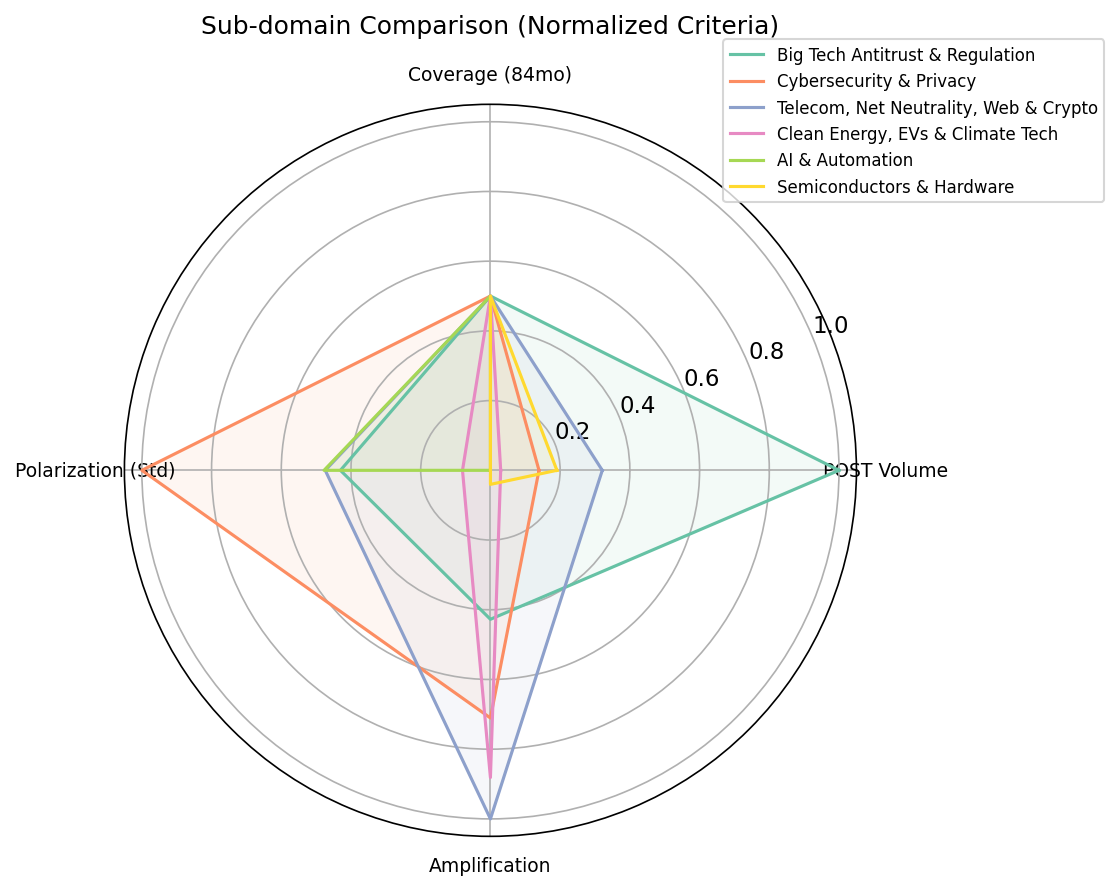

02:59:18 | INFO | Chart 10 saved -> 10_subdomain_radar.pdf


In [50]:
# --- Chart 10: Radar / Spider chart — 6 sub-domains on 4 criteria (normalized) ---
from math import pi

categories = list(WEIGHTS.keys())
N_cat = len(categories)

# Prepare angles for radar chart
angles = [n / float(N_cat) * 2 * pi for n in range(N_cat)]
angles += angles[:1]  # close the polygon

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = sns.color_palette("Set2", n_colors=len(SUBDOMAIN_TAXONOMY))

for (_, row), color in zip(norm_df.iterrows(), colors):
    values = [row[c + "_norm"] for c in categories]
    values += values[:1]
    ax.plot(angles, values, linewidth=1.5, label=row["Sub-domain"], color=color)
    ax.fill(angles, values, alpha=0.08, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title("Sub-domain Comparison (Normalized Criteria)", y=1.08, fontsize=12)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "10_subdomain_radar.pdf"))
plt.show()
logger.info("Chart 10 saved -> 10_subdomain_radar.pdf")

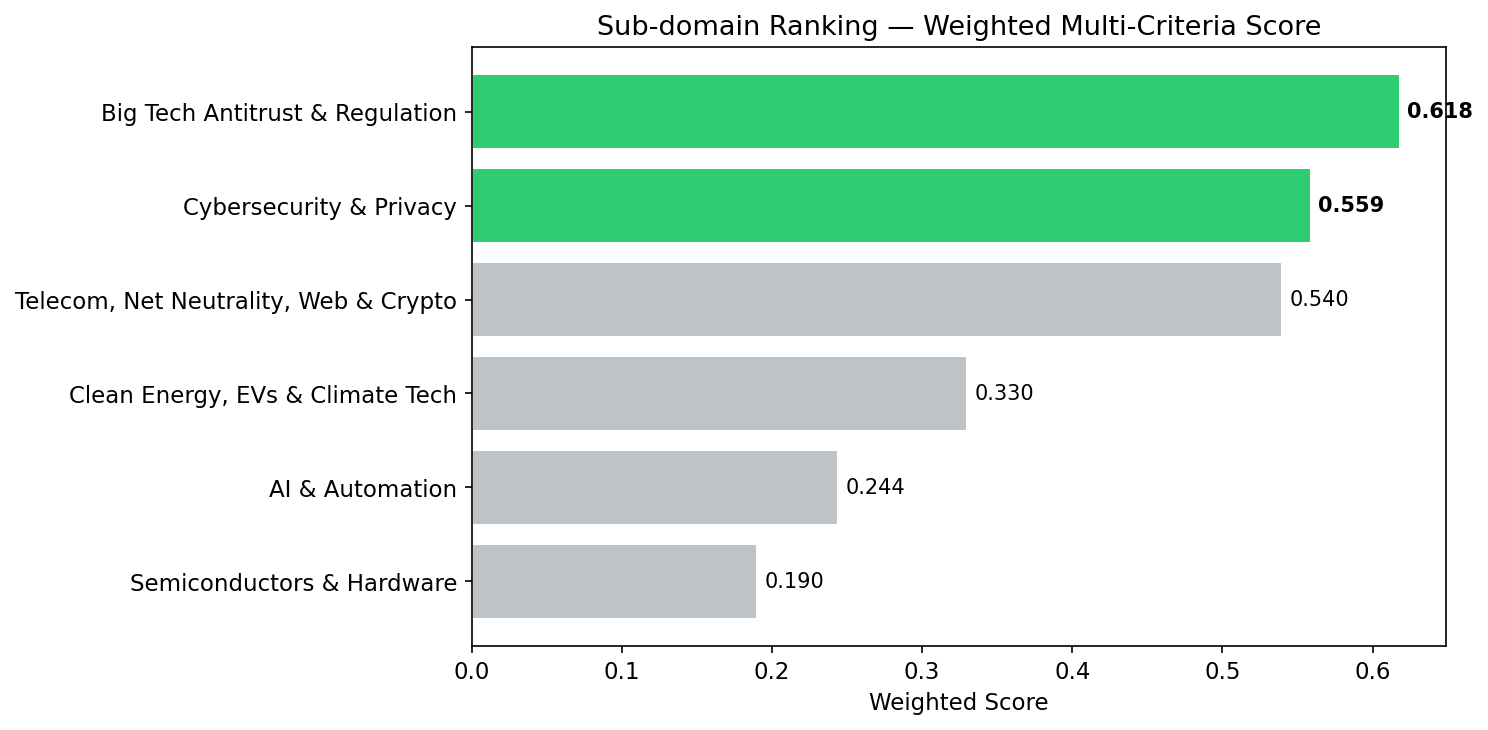

02:59:19 | INFO | Chart 11 saved -> 11_subdomain_ranking.pdf


In [51]:
# --- Chart 11: Final weighted score ranking bar chart ---
fig, ax = plt.subplots(figsize=(10, 5))

colors_rank = ["#2ecc71" if i < 2 else "#bdc3c7" for i in range(len(norm_df))]
ax.barh(
    norm_df["Sub-domain"], norm_df["Weighted_Score"],
    color=colors_rank, edgecolor="white",
)
ax.set_xlabel("Weighted Score")
ax.set_title("Sub-domain Ranking — Weighted Multi-Criteria Score")
ax.invert_yaxis()

for i, (_, row) in enumerate(norm_df.iterrows()):
    ax.text(
        row["Weighted_Score"] + 0.005, i,
        f"{row['Weighted_Score']:.3f}", va="center", fontsize=10,
        fontweight="bold" if i < 2 else "normal",
    )

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "11_subdomain_ranking.pdf"))
plt.show()
logger.info("Chart 11 saved -> 11_subdomain_ranking.pdf")

# 10. SUMMARY & ACTIONABLE RECOMMENDATIONS FOR PIPELINE

### 10.1. Quy tắc Làm sạch Dữ liệu cho `scripts/preprocessing/clean_data.py` (Evidence-Based từ Part A)

| STT | Hạng mục xử lý | Bằng chứng số liệu từ EDA (11,766,134 dòng) | Quy tắc triển khai cụ thể trong `clean_data.py` |
| :-: | :--- | :--- | :--- |
| **1** | **Giải mã HTML Entities** | **856,739 dòng (7.281%)** chứa mã HTML (`&gt;` 1,076,295 lần; `&amp;` 300,242 lần; `&lt;` 22,171 lần). Từ rác `amp` xuất hiện 16,965 lần trong Top N-grams. | Chạy `html.unescape()` đầu tiên trên cột `content` trước mọi bước xử lý chuỗi khác. |
| **2** | **Làm sạch URL & Markdown** | **592,480 dòng (5.035%)** chứa URL thô; **531,611 dòng (4.518%)** chứa `**`; **323,889 dòng (2.753%)** chứa link `[text](url)`; **21,603 dòng (0.184%)** chứa `~~`. | Dùng Regex đổi `[text](url)` -> `text`, xóa toàn bộ `https?://\S+`, xóa ký tự đánh dấu `**`, `~~`, `` ` `` và dấu trích dẫn `>` đầu dòng. |
| **3** | **Cắt hậu tố `[removed]` dính liền, Lọc Placeholder & Sinh `content_hash`** | Chỉ có **78 dòng** khớp chính xác hoàn toàn với `[deleted]`/`[removed]`/rỗng, nhưng từ khóa `removed` xuất hiện tới **83,214 lần** ở đuôi các bài `POST` chưa phân loại. | Dùng Regex xóa hậu tố `\[removed\]$` và `\[deleted\]$` bị nối vào cuối tiêu đề `POST`; loại bỏ các dòng rỗng, khoảng trắng hoặc giả-null (`"nan"`, `"none"`, `"null"`). Đồng thời tạo cột `content_hash` (MD5 hex của chuỗi đã chuẩn hóa) theo chuẩn `docs/embedding_input_requirements.md` để hỗ trợ deduplicate và tái sử dụng embedding. |
| **4** | **Loại bỏ Bot, Spam & AutoModerator** | **385,663 dòng (3.28%)** trùng lặp chính xác (riêng `POST` là **11.23%**). Chuỗi spam `"Message de test vraie hein[removed]"` lặp lại **13,596 lần** (100% từ Top-20 user); 13/20 mẫu đầu là thông báo xóa bài của AutoModerator (38.6% -> 98.3% từ Top-20 user). | Lọc bỏ toàn bộ dòng khớp mẫu AutoModerator (`^Thank you for your (submission\|comment)! Unfortunately, it has been removed`), chuỗi `"Message de test vraie hein"`, `"[deleted by user]"` và khử trùng lặp chính xác trên `POST` qua `content_hash`. |
| **5** | **Ngưỡng độ dài tối thiểu (`word_count`)** | `< 3 alpha chars`: 3,858 POST (0.46%) & 8,969 COMMENT (0.08%). `< 3 từ`: 23,335 POST (2.75%) & 263,941 COMMENT (2.42%). `< 5 từ`: 91,225 POST (10.76%) & 777,533 COMMENT (7.12%). | Loại bỏ mọi dòng có `< 3 ký tự chữ cái`. Áp dụng ngưỡng lọc độ dài linh hoạt: giữ `POST >= 3 từ` (bảo toàn tiêu đề tin tức ngắn) và `COMMENT >= 5 từ` (loại bỏ câu cảm thán cụt lủn như `"Source?"`, `"Why?"`, `"What?"`). |
| **6** | **Cấu hình SBERT `max_seq_length`** | Chỉ có **0.14% POST (1,187 bài)** và **1.87% COMMENT (204,241 dòng)** vượt quá 200 từ (~256 tokens). P99 của POST = 43 từ, P99 của COMMENT = 258 từ. | Giữ nguyên mô hình `all-MiniLM-L6-v2` với `max_seq_length = 256 tokens` — bảo toàn trọn vẹn ngữ nghĩa của **99.86% POST** và **98.13% COMMENT** với tốc độ nhúng nhanh nhất. |

---

### 10.2. Quyết định Thu hẹp Phạm vi Ngách Chủ đề (Sub-domain Scoping từ Part B)

Dựa trên bảng chấm điểm đa tiêu chí (`11_subdomain_ranking.pdf`) và ma trận giao thoa (`06_subdomain_overlap_heatmap.pdf`), chúng tôi đề xuất lựa chọn **Tổ hợp 2 Ngách Dẫn đầu (hoặc kết hợp thêm Ngách Hạng 3)** làm tập dữ liệu mục tiêu cho toàn bộ pipeline **NarrativeCast (RQ1 -> RQ3)**:

1. **Ngách Chủ đạo 1 — Big Tech Antitrust & Regulation (Hạng 1 — Score: 0.618):**
   - Cung cấp nền tảng lưu lượng lớn nhất (**113,204 POSTs**, trung bình ~1,350 POSTs/tháng) và liên tục tuyệt đối trong 84 tháng, đảm bảo chuỗi thời gian dày đặc cho các mô hình học sâu (LSTM, GRU, PatchTST/iTransformer).
2. **Ngách Chủ đạo 2 — Cybersecurity & Privacy (Hạng 2 — Score: 0.559):**
   - Sở hữu **độ phân cực cảm xúc cao nhất (`Std = 0.3810`, `Mean = -0.0224`)** và sắc thái đối lập rõ nét nhất giữa `POST` và `COMMENT`, tạo điều kiện lý tưởng cho thuật toán **BERTopic + HDBSCAN** tách biệt các luồng quan điểm (narratives) xung đột bên trong cùng một chủ đề. Hơn nữa, ngách này có sự giao thoa tự nhiên **17.1%** với *Big Tech*, tạo thành một hệ sinh thái chủ đề liền mạch (*"Quyền lực Big Tech, An ninh mạng & Quyền riêng tư dữ liệu"*).
3. **Ngách Bổ trợ / Kiểm thử Sự kiện Đột biến — Telecom, Net Neutrality, Web & Crypto (Hạng 3 — Score: 0.540):**
   - Sở hữu hệ số khuếch đại bình luận cao nhất (**15.09 COMMENT/POST**) và chứa **cú spike lịch sử tháng 11–12/2017 (~1,600 POSTs/tháng)** xoay quanh sự kiện FCC bãi bỏ Net Neutrality — cực kỳ giá trị để làm tập kiểm thử khả năng phát hiện sớm sự bùng phát/suy tàn của luồng quan điểm (**Early Warning / Lifecycle Shift Detection ở RQ3**).

In [52]:
# --- Ensure summary report template exists in outputs/reports/content_eda_summary.md ---
# This document will be populated in Step 2 (Markdown & Report) after
# the user validates the numerical outputs and generated PDF charts.

report_dir = "../outputs/reports/"
os.makedirs(report_dir, exist_ok=True)
report_path = os.path.join(report_dir, "content_eda_summary.md")

if not os.path.exists(report_path):
    logger.info("Initializing report template at %s", report_path)
else:
    logger.info("Report template already exists at %s (preserved)", report_path)


02:59:19 | INFO | Report template already exists at ../outputs/reports/content_eda_summary.md (preserved)
